# UrbanStay: Прогнозирование риска отмены бронирования

- Автор: Евдокимов Александр
- Дата: 29.10.26

---

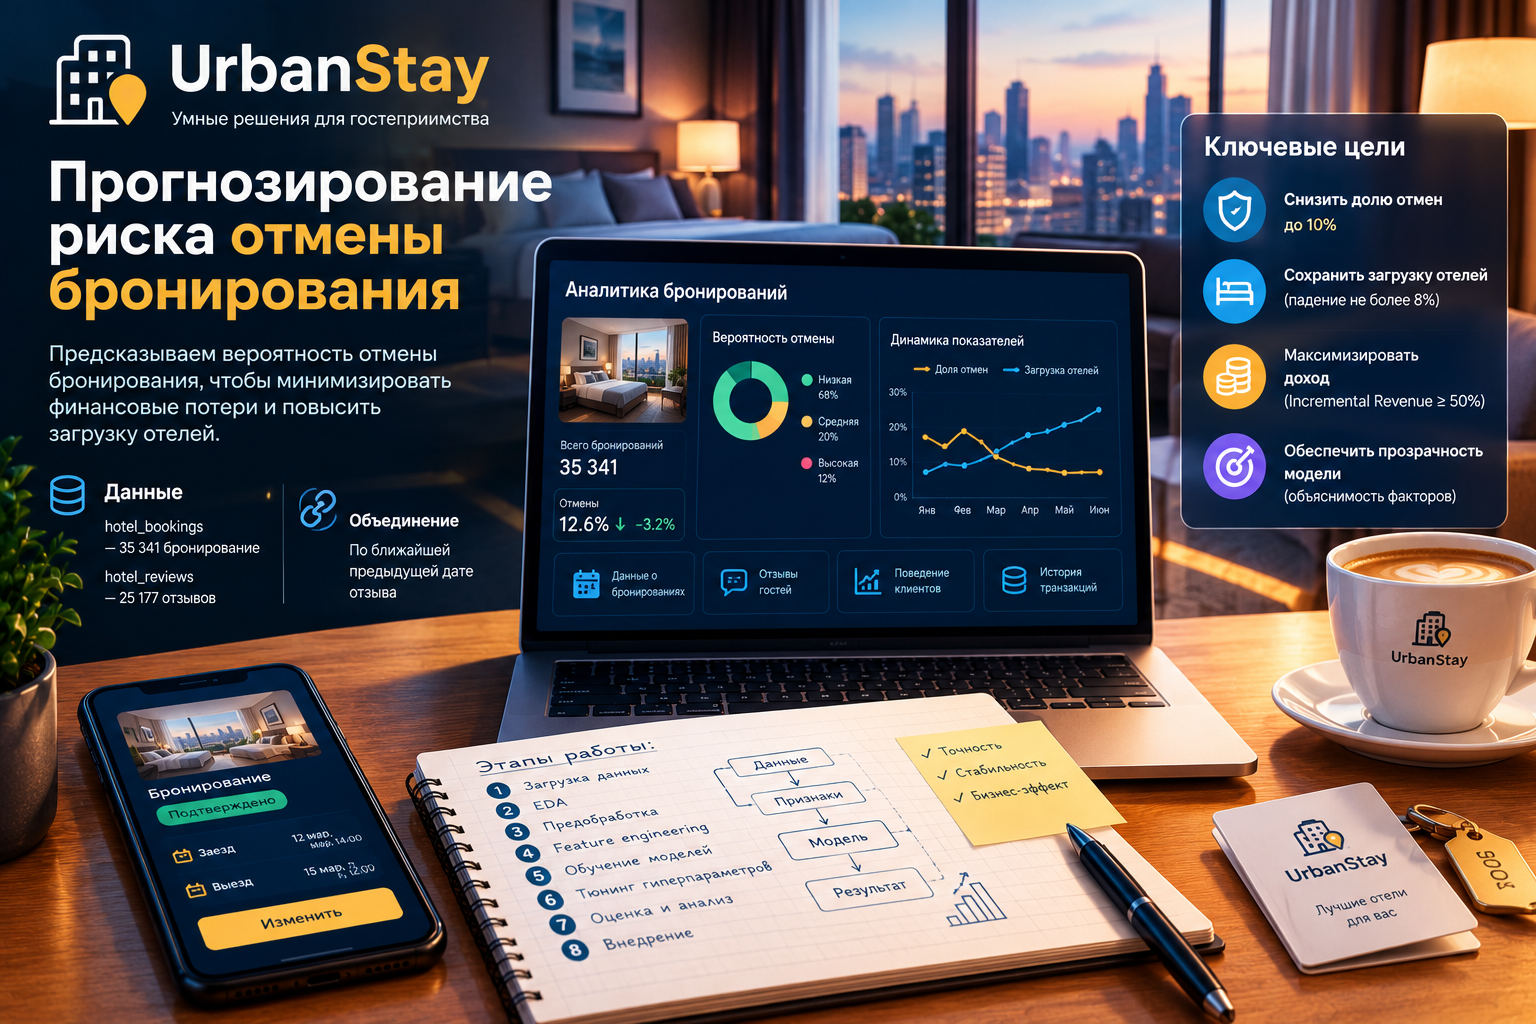

<a id='p1'></a>

---

## Цель и задачи проекта

### Цель проекта

Разработать модель машинного обучения, прогнозирующую вероятность отмены бронирования номера в сети отелей среднего сегмента `UrbanStay`. Модель должна минимизировать финансовые потери, связанные с поздними отменами, и по возможности повышать загрузку отелей.

Основная задача проекта - не просто получить точный прогноз, но и максимизировать экономический эффект от внедрения модели. Для этого необходимо оценить три ключевых бизнес-показателя: динамику доли отмен бронирования, динамику загрузки отелей и прирост дохода (`Incremental Revenue`, сокращенно - `IR`).

Дополнительным требованием является прозрачность работы модели: необходимо определить наиболее значимые признаки, влияющие на отмену брони, и проверить, соответствует ли поведение модели бизнес-логике.

### Задачи проекта

В рамках указанной цели необходимо решить задачу бинарной классификации. Для этого требуется выполнить следующие шаги:
1. Выгрузить данные о бронированиях `hotel_bookings` и отзывах `hotel_reviews` из базы данных с помощью SQL-запросов.
2. Провести исследовательский анализ данных: изучить распределение целевой переменной, пропуски, дубликаты, аномалии.
3. Объединить таблицу отзывов с таблицей бронирований.
4. Выполнить feature engineering: создать не менее трёх новых признаков на основе данных о брони.
5. Создать новые признаки на основе текстов отзывов с помощью инструментов векторизации.
6. Разделить данные на обучающую, калибровочную и тестовую выборки (60/20/20).
7. Обучить не менее двух моделей из списка: `Random Forest`, `CatBoost`, `LightGBM`, `XGBoost` или любую другую.
8. Провести кросс-валидацию с тремя фолдами и оптимизировать гиперпараметры с помощью `Optuna`, используя в качестве ключевой метрики `IR`.
9. Откалибровать лучшую модель на полной тренировочной выборке.
10. Найти оптимальный порог классификации, при котором достигается максимальный `IR`.
11. Сравнить матрицы ошибок и `IR` на калибровочной и тестовой выборках для проверки стабильности.
12. Оценить важность признаков с помощью `SHAP` или встроенных инструментов модели.
13. Рассчитать экономическую эффективность модели: динамику доли отмен, динамику загрузки, `IR` и относительный `IR`.
14. Сформулировать итоговые выводы и рекомендации для бизнеса.

<a id='p2'></a>

---

## Постановка задачи машинного обучения

Задача проекта относится к обучению с учителем и является задачей бинарной классификации. Для каждого бронирования необходимо предсказать вероятность того, что оно будет отменено.

**Целевая переменная:**
- `booking_status` - статус бронирования: `отказ_брони` (бронь отменена) или `нет_отказа` (бронь активна, не отменена).

Модель должна выдавать вероятность отмены. На основе этой вероятности и подобранного порога классификации принимается решение о том, относить ли бронь к рискованным.

В качестве моделей для сравнения будут рассмотрены:
1. `LogisticRegression` - классическая линейная логистическая регрессия.
2. `Random Forest` - ансамбль решающих деревьев.
3. `CatBoost` - библиотека градиентного бустинга, хорошо работающая с категориальными признаками.
4. `LightGBM` - библиотека градиентного бустинга с эффективным обучением деревьев по листьям.
5. `XGBoost` - библиотека градиентного бустинга над решающими деревьями.

Для всех моделей необходимо использовать одинаковые обучающие, калибровочные и тестовые выборки, чтобы сравнение было корректным.

### Метрики оценки

#### Технические метрики

Качество моделей будет оцениваться с помощью технических и бизнес-метрик.
- `Accuracy` - доля правильных ответов;
- `Precision` - точность (доля истинно положительных среди предсказанных положительных);
- `Recall` - полнота (доля истинно положительных среди всех реальных положительных);
- `F1-мера` - гармоническое среднее точности и полноты;
- `ROC-AUC` - площадь под ROC-кривой;
- `PR-AUC` - площадь под кривой «точность–полнота» (Precision-Recall AUC), также известная как `Average Precision`.

Для оценки качества калибровки будем использовать следующие метрики:
- `коэффициента Бриера` - среднее значение квадратов разностей между предсказанной вероятностью и фактическим исходом.
- `ECE` (Expected Calibration Error) - метрика, которая показывает, насколько в среднем предсказанные моделью вероятности соответствуют реальной частоте событий.
- `MCE` (Maximum Calibration Error) - метрика, которая показывает, насколько сильно вероятности, предсказанные моделью, могут расходиться с реальной частотой событий в наихудшем случае.

#### Бизнес метрики

Однако **ключевой метрикой** для бизнеса является `IR`, поскольку она показывает, насколько выгодно внедрение модели в финансовом выражении. В рамках расчета будем различать две версии показателя:

<span style="font-size: 14px;">**1. Абсолютное значение**</span>
$$
\text{IRa} = \text{IR}_{\text{после}} - \text{IR}_{\text{до}}.
$$ 

Доход до применения модели:
$$
\text{IR}_{\text{до}} = \text{TotalSuccess} \times \text{AvgRev} - \text{TotalCancellations} \times \text{LostRev}.
$$

Доход после внедрения модели:
$$
\text{IR}_{\text{после}} = \text{TP} \times \text{PerRebooking} + \text{TN} \times \text{AvgRev} - \text{FP}\times\text{CostFP} - \text{FN}\times\text{LostRev}
$$

<span style="font-size: 14px;">**2. Относительное значение**</span>
$$
\text{IRs} = \frac{\text{IR}_{\text{после}} - \text{IR}_{\text{до}}}{\text{IR}_{\text{до}}} \times 100\%
$$

*Целевое значение:* относительный `IRs` должен составить **не менее 50%**.

В этих формулах:
- `TotalSuccess` - все успешные брони, которые состоялись и были оплачены.
- `AvgRev` = 64 500 руб. - средний доход от сдачи одного номера.
- `TotalCancellations` - все отмены бронирования.
- `LostRev` = 64 500 руб. - упущенный доход от отмены одного бронирования. Равен `AvgRev`, если нет других факторов.
- `TP` - верно предсказанные отмены бронирования.
- `PerRebooking` = 45 000 руб. - стоимость повторной сдачи номеров, бронь на которые отменилась. Вовремя замеченная отмена даёт возможность сдать номер кому-то другому, это обеспечивает дополнительную прибыль.
- `TN` - количество случаев, когда модель не предсказала отмены и бронь действительно состоялась, гость вовремя заехал и оплатил номер.
- `FP` - ложные отмены бронирования - модель предсказала отмену, но гости приехали.
- `CostFP` = 7 000 руб. - стоимость одного ложного предсказания отмены бронирования, компенсации, ущерб от потери лояльности, административные издержки.
- `FN` - пропущенные отмены - модель не предсказала отмену, но она произошла.

Дополнительно используются две бизнес-метрики:

<span style="font-size: 14px;">**3. Динамика доли отмен бронирования**</span>

Показывает, насколько снизилась доля отмен после внедрения модели:

$$
\text{Динамика отмен} = \frac{\text{Доля отмен до} - \text{Доля отмен после}}{\text{Доля отмен до}} \times 100\%
$$

Здесь:
- $\text{Доля отмен до} = \text{Фактические отмены } / \text{ Общее количество броней}$ - здесь анализируются данные из датафрейма. `Фактические отмены` - сумма единиц в целевой переменной, а общее количестов броней - просто число строк.
- $\text{Доля отмен после} = \text{FN } / \text{ Общее количество броней}$ - `FN` - пропущенные  моделью отмены бронирования. 
- **Целевое значение:** доля отмен после внедрения модели должна составить **10%**.

<span style="font-size: 14px;">**4. Динамика загрузки отеля**</span>

Показывает, как изменилась загрузка отелей после внедрения модели. В виду отсутствия номерного фонда отеля расчет осуществляется через брони. Одна бронь приравнивается к одному номеру.

$$
\text{Динамика загрузки} = \frac{\text{Загрузка до} - \text{Загрузка после}}{\text{Загрузка до}} \times 100\%
$$

Здесь:
- $\text{Загрузка до} = \text{занятые_до } / \text{ Общее количество броней}$. $\text{Общее количество броней}$ - просто число строк в датафрейме.
    * $\text{занятые_до} = \text{Общее количество броней} - \text{Фактические отмены}$. Оба показателя введены ранее.
- $\text{Загрузка после} = \text{TN } / \text{ Общее количество броней}$

Целевое значение: загрузка отеля не должна уменьшиться больше чем на **8%** после внедрения модели.

Таким образом, при выборе лучшей модели необходимо учитывать одновременно:
- высокие технические метрики (`F1`, `ROC-AUC`, `PR-AUC`);
- максимальный `IR`;
- снижение доли отмен до 10%;
- сохранение загрузки отелей (падение не более чем на 8%).

### Интерпретация модели

Для лучшей модели необходимо провести анализ важности признаков с помощью `SHAP` или встроенных инструментов. Основные задачи интерпретации:
1. Определить топ-10 признаков, которые сильнее всего влияют на отмену брони.
2. Проверить, соответствует ли влияние признаков бизнес-логике.
3. Оценить влияние текстовых признаков, созданных на основе отзывов.
4. Сделать выводы о том, какие факторы повышают и снижают риск отмены.

<a id='p3'></a>

---

## Описание данных

Для построения моделей предоставлены два источника данных, которые необходимо выгрузить с помощью SQL-запросов.

### Данные об истории бронирования: `hotel_bookings`

Содержит информацию о бронированиях номеров в гостинице. Каждая строка — это отдельная бронь. Всего в таблице **35 341** случай бронирования.

| Признак | Описание |
|---|---|
| `booking_id` | Уникальный номер брони |
| `booking_date` | Дата оформления брони |
| `sales_channel` | Способ оформления брони: офлайн, онлайн, корпоративное |
| `adult_count` | Количество взрослых гостей |
| `child_count` | Количество детей |
| `returning_customer` | 1 - клиент уже бронировал, 0 - новый клиент |
| `previous_cancellations` | Количество отменённых бронирований в прошлом |
| `previous_no_shows` | Количество не явок клиента в отель ранее: 0, 1, 2 и т.д. |
| `booking_value` | Итоговая стоимость бронирования в рублях |
| `days_until_checkin` | Количество дней между бронью и заездом |
| `weekend_nights` | Количество ночей в выходные дни |
| `weekday_nights` | Количество ночей в будние дни |
| `meal_plan` | Выбранный тип питания |
| `parking_included` | Информация о бронировании парковки |
| `room_type` | Категория номера |
| `customer_special_requests` | Количество комментариев и пожеланий клиента |
| `booking_status` | **Целевая переменная**: `отказ_брони` или `нет_отказа` |

### Данные по истории отзывов о проживании: `hotel_reviews`

Содержит информацию об отзывах гостей, которые заселялись в отель. Всего в ней **25 177** отзывов о проживании. Некоторые гости приезжали в отели сети много раз, поэтому могли оставить несколько отзывов.

| Признак | Описание |
|---|---|
| `customer_id` | Уникальный идентификатор клиента |
| `booking_id` | Идентификатор брони, по которой оставлен отзыв |
| `review_date` | Дата, когда клиент оставил отзыв |
| `stay_rating` | Оценка проживания: 1 - низший балл, 5 - высший балл |
| `review_text` | Развёрнутый комментарий клиента о проживании |

### Особенности объединения данных

Для объединения таблиц необходимо использовать следующее правило: для каждой даты бронирования в столбце `booking_date` нужно взять комментарий и оценку клиента по **предыдущей ближайшей дате** отзывов, указанной в столбце `review_date`. Это позволит связать обратную связь клиента с конкретным периодом проживания, что критически важно для анализа удовлетворённости гостей.

**Пример:**
- В таблице бронирований есть строка с `booking_date = 01.02.2025`.
- У клиента есть два прошлых отзыва: `review_date = 01.02.2024` и `review_date = 01.12.2024`.
- Ближайшая к `01.02.2025` дата - `01.12.2024`. Значит, комментарий и оценка от `01.12.2024` подтягиваются к строке с `booking_date = 01.02.2025`.

<a id='contents'></a>

---

<span style="font-size: 18px;">**Оглавление**</span>

1. [Цель и задачи проекта](#p1)
2. [Постановка задачи машинного обучения](#p2)
3. [Описание данных](#p3)
4. [Загрузка библиотек и данных](#p4)
5. Исследовательский анализ данных (EDA)
- [Пропуски, выбросы, дубликаты, аномалии](#p5a)
- [Объединение таблиц и создание новых признаков](#p5b)
- [Корреляция](#p5c)
- [Выводы по EDA](#p5d)
6. Определение лучшей модели
- [Предобработка](#p6a)
- [Кросс-валидация моделей](#p6b)
- [Оптимизация гиперпараметров](#p6c)
- [Выбор, калибровка модели](#p6d)
- [Определение порога и анализ матрицы классификаций](#p6e)
- [Оценка важности признаков](#p6f)
7. [Итоговые выводы и рекомендации](#p7)

<a id='p4'></a>

---

## Загрузка библиотек и данных

[К Содержимому проекта](#contents)

In [1]:
# Установка библиотек
#!pip install optuna -Uq
#!pip install dotenv -Uq
#!pip install shap -Uq
#!pip install scikit-learn -Uq
#!pip install phik -Uq
#!pip install imblearn -Uq
#!pip install lightgbm -Uq
#!pip install xgboost -Uq
#!pip install catboost -Uq

try:
    !pip freeze > "../requirements.txt"
except Exception:
    !pip freeze > "requirements.txt"

In [2]:
# Основные библиотеки для работы с датафреймами, визуализацией, а также вспомогательные
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import joblib
from time import time
import sys

# Соединение с БД
from sqlalchemy import create_engine
from dotenv import load_dotenv, dotenv_values, set_key
import os

# Модели
from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import lightgbm as lgb #LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Предобработка и пайплайн
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Для создания собственного ColumnTransformer для GB моделей
from scipy.sparse import csr_matrix, hstack
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin

# Обработка текста
from sklearn.feature_extraction.text import TfidfVectorizer
import nltk
from nltk.corpus import stopwords
import pymorphy3
from functools import lru_cache # для кэширования лемм

# Поиск гиперпараметров
import optuna
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

# Оценка важности признаков
import shap

# Метрики
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix
)


# Модули для калибровки
from sklearn.calibration import calibration_curve, CalibrationDisplay, CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

# Оценка корреляции
from phik import phik_matrix
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Балансировка классов
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler


# 2 дополнительных класса: color для более качественного вывода, а glob_const - константы, используемые по проекту
class color:
    """
    Класс для форматирования текста в терминале
    """

    PURPLE = "\033[95m"
    CYAN = "\033[96m"
    DARKCYAN = "\033[36m"
    BLUE = "\033[94m"
    GREEN = "\033[92m"
    YELLOW = "\033[93m"
    RED = "\033[91m"
    BOLD = "\033[1m"
    UNDERLINE = "\033[4m"
    END = "\033[0m"  # сбросить все стили (возврат к нормальному виду)
    
class glob_const:
    RANDOM_STATE = 42
    AVG_REV = 64500 
    LOST_REV = 64500
    PER_REBOOK = 45000 
    COST_FP = 7000
    min_df_cl = 5 # выкинуть редкие слова/биграммы из отзывов клиента
    max_features_cl = 500 #Ограничение на количество слов в словаре отзывов клиента
    min_df_pd = 3 # выкинуть редкие слова/биграммы из отзывов на предыдущую дату
    max_features_pd = 200 #Ограничение на количество слов в отзывах на предыдущую дату
    scale_pos_weight = 71.2 / 28.8

In [3]:
# Запись данных в файл. Нужно для платформы
#db_config = {'user': '...', 
#             'pwd': '...',
#             'host': '...',
#             'port': 1000, 
#             'db': '...'
#             }
#for key, value in db_config.items():
#    set_key('db_connection.env', key, str(value), quote_mode='never')

# Подгатовка конфигурации
load_dotenv(dotenv_path='./db_connection.env')
db_config = {'user': os.getenv('user'), 
             'pwd': os.getenv('pwd'),
             'host': os.getenv('host'),
             'port': int(os.getenv('port')), 
             'db': os.getenv('db')
             }
connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db'],
)
engine = create_engine(connection_string)

In [4]:
query1 = '''
SELECT *
FROM hotel_bookings b
'''
query2 = '''
SELECT *
FROM hotel_reviews r
'''

In [5]:
try:
    df_bookings = pd.read_sql_query(query1, con=engine)
    df_reviews = pd.read_sql_query(query2, con=engine)
except Exception:
    df_reviews = pd.read_csv('./../datasets/hotel_reviews.csv')
    df_bookings = pd.read_csv('./../datasets/hotel_bookings.csv')

In [6]:
for df in [df_bookings, df_reviews]:
    
    print(color.BOLD + color.PURPLE + '\nИнформация: ' + color.END)
    print(color.BOLD + color.BLUE + 'Случайные пять строк:' + color.END)
    display(df.sample(n=5, random_state = glob_const.RANDOM_STATE))
    print(color.BOLD + color.RED + '\nОсновая информация по датасету:\n' + color.END)
    df.info()
    print(color.BOLD + color.GREEN + '\nСтатистическая информация по датасету:\n' + color.END)
    display(df.describe().T)
    display(df.select_dtypes(include=["object", "string", "category"]).describe().T)


Информация: 
Случайные пять строк:


,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
7123,INN07116,2019-05-09,офлайн_бронирование,3,0,False,2,0,нет_отказа,26800.0,150,4,0,тип_питания_1,False,тип_1,1
2858,INN02858,2021-02-17,офлайн_бронирование,1,0,True,1,2,отказ_брони,8900.0,209,1,0,тип_питания_1,False,тип_1,0
24193,INN24191,2020-09-08,онлайн_бронирование,3,2,False,1,0,отказ_брони,113900.0,89,13,4,тип_питания_1,False,тип_1,0
4448,INN04444,2019-05-26,онлайн_бронирование,2,0,True,2,1,отказ_брони,67000.0,7,8,2,тип_питания_1,False,тип_1,2
31638,INN20388,2021-05-25,корпоративное_бронирование,1,2,True,2,2,нет_отказа,6700.0,130,1,0,тип_питания_1,False,тип_1,0



Основая информация по датасету:

<class 'pandas.DataFrame'>
RangeIndex: 35341 entries, 0 to 35340
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   booking_id                 35341 non-null  str    
 1   booking_date               35341 non-null  object 
 2   sales_channel              35341 non-null  str    
 3   adult_count                35341 non-null  int64  
 4   child_count                35341 non-null  int64  
 5   returning_customer         35341 non-null  bool   
 6   previous_cancellations     35341 non-null  int64  
 7   previous_no_shows          35341 non-null  int64  
 8   booking_status             35341 non-null  str    
 9   booking_value              35341 non-null  float64
 10  days_until_checkin         35341 non-null  int64  
 11  weekday_nights             35341 non-null  int64  
 12  weekend_nights             35341 non-null  int64  
 13  meal_plan              

,count,mean,std,min,25%,50%,75%,max
adult_count,35341.0,12.479726,45.726290,1.0,1.0,2.0,3.0,300.0
child_count,35341.0,0.358988,0.587324,0.0,0.0,0.0,1.0,2.0
previous_cancellations,35341.0,0.356923,0.628771,0.0,0.0,0.0,1.0,5.0
previous_no_shows,35341.0,0.839535,0.931724,0.0,0.0,1.0,1.0,5.0
booking_value,35341.0,61634.055219,42837.589968,0.0,33500.0,53600.0,80400.0,417221.2
days_until_checkin,35341.0,100.523726,71.872677,2.0,45.0,90.0,144.0,300.0
weekday_nights,35341.0,6.532922,3.339492,1.0,5.0,6.0,9.0,15.0
weekend_nights,35341.0,1.953991,1.477249,0.0,0.0,2.0,2.0,6.0
customer_special_requests,35341.0,0.621488,0.784391,0.0,0.0,0.0,1.0,5.0


,count,unique,top,freq
booking_id,35341,30733,INN00327,4
booking_date,35341,2445,2019-06-03,39
sales_channel,35341,3,офлайн_бронирование,12040
booking_status,35341,2,нет_отказа,25177
meal_plan,35341,5,тип_питания_1,27182
room_type,35341,7,тип_1,27197



Информация: 
Случайные пять строк:


,customer_id,booking_id,review_date,stay_rating,review_text
10727,C8037,INN15057,2019-01-21,4,Отличный отель! удобные подушки и матрасы. оте...
5508,C4115,INN07658,2020-01-16,3,"Неплохо. спа‑услуги на отлично, но не работает..."
3706,C2748,INN05128,2021-03-02,3,"Неплохо. красивое оформление территории, но гр..."
15556,C11702,INN21831,2018-11-09,3,"Неплохо. дружелюбная атмосфера, но грубый перс..."
3794,C2806,INN05243,2018-09-15,3,"Неплохо. быстрый интернет, но неудобная мебель..."



Основая информация по датасету:

<class 'pandas.DataFrame'>
RangeIndex: 25177 entries, 0 to 25176
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   customer_id  25177 non-null  str   
 1   booking_id   25177 non-null  str   
 2   review_date  25177 non-null  object
 3   stay_rating  25177 non-null  int64 
 4   review_text  25177 non-null  str   
dtypes: int64(1), object(1), str(3)
memory usage: 983.6+ KB

Статистическая информация по датасету:



,count,mean,std,min,25%,50%,75%,max
stay_rating,25177.0,3.395321,0.541434,2.0,3.0,3.0,4.0,5.0


,count,unique,top,freq
customer_id,25177,13429,C4486,8
booking_id,25177,21883,INN01741,4
review_date,25177,2514,2020-06-12,29
review_text,25177,14153,Отличный отель! хорошие виды из окон.,42


**Выводы:**

1. Загрузка прошла успешно. 
2. Явные пропуски не выявлены. 
3. Заметны дубликаты по `booking_id` в таблице `hotel_bookings`, нужно внимательно проверить на дубли и аномалии. 
4. Типы не всегда соответствуют ожиданиям, `booking_date` имеет тип строки, хотя это дата.
5. Имена столбцов соответствуют стандарту, принятому в Python.
6. В `adult_count` есть явные выбросы. Можно или поменять на медиану или удалить.
7. Заметны дубликаты по `booking_id` в таблице `hotel_reviews`. Нужно аккуратно объединять данные, учитывая алгоритм, описанный во введении.

<a id='p5a'></a>

---

## Исследовательский анализ данных (EDA)

### Пропуски, выбросы, дубликаты, аномалии

[К Содержимому проекта](#contents)

Рассмотрим уникальные значения в столбцах.

In [7]:
def print_unique(df):
    ser = df.nunique().sort_values(ascending = True)
    print(color.BOLD + color.BLUE + 'Количество уникальных значений:' + color.END)
    display(ser)
    ind = ser.index
    fl = True
    i = -1
    while fl:
        i += 1
        col = ind[i]
        if ser[col] <=150:
            print(color.RED + '\nУникальные значения в столбце ' + col + ':\n' + color.END)
            display(sorted(df[col].unique()))
        else:
            fl = False

print_unique(df_bookings)

Количество уникальных значений:


returning_customer               2
booking_status                   2
parking_included                 2
sales_channel                    3
child_count                      3
weekend_nights                   4
meal_plan                        5
adult_count                      6
previous_no_shows                6
previous_cancellations           6
customer_special_requests        6
room_type                        7
weekday_nights                  14
days_until_checkin              79
booking_value                 1766
booking_date                  2445
booking_id                   30733
dtype: int64


Уникальные значения в столбце returning_customer:



[np.False_, np.True_]


Уникальные значения в столбце booking_status:



...

['тип_1', 'тип_2', 'тип_3', 'тип_4', 'тип_5', 'тип_6', 'тип_7']


Уникальные значения в столбце weekday_nights:



[np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(9),
 np.int64(10),
 np.int64(11),
 np.int64(12),
 np.int64(13),
 np.int64(15)]


Уникальные значения в столбце days_until_checkin:



[np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(10),
 np.int64(11),
 np.int64(12),
 np.int64(15),
 np.int64(18),
 np.int64(19),
 np.int64(21),
 np.int64(24),
 np.int64(25),
 np.int64(28),
 np.int64(34),
 np.int64(45),
 np.int64(50),
 np.int64(55),
 np.int64(62),
 np.int64(63),
 np.int64(67),
 np.int64(69),
 np.int64(71),
 np.int64(72),
 np.int64(73),
 np.int64(75),
 np.int64(76),
 np.int64(77),
 np.int64(79),
 np.int64(80),
 np.int64(83),
 np.int64(85),
 np.int64(87),
 np.int64(88),
 np.int64(89),
 np.int64(90),
 np.int64(92),
 np.int64(94),
 np.int64(96),
 np.int64(97),
 np.int64(100),
 np.int64(103),
 np.int64(106),
 np.int64(109),
 np.int64(111),
 np.int64(114),
 np.int64(115),
 np.int64(117),
 np.int64(121),
 np.int64(122),
 np.int64(123),
 np.int64(124),
 np.int64(126),
 np.int64(130),
 np.int64(135),
 np.int64(144),
 np.int64(145),
 np.int64(150),
 np.int64(157),
 np.int64(160),
 np.int64(175),
 np.int64(181),
 np.int64(

In [8]:
print_unique(df_reviews)

Количество уникальных значений:


stay_rating        4
review_date     2514
customer_id    13429
review_text    14153
booking_id     21883
dtype: int64


Уникальные значения в столбце stay_rating:



[np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

**Выводы:**

В большинстве столбцов с небольшим количеством уникальных значений (почти все, кроме `booking_value`, `booking_date`, `booking_id`, `review_date`, `customer_id`, `review_text`) аномалий нет. Исключения:
1. `weekend_nights` - уникальные значения 0, 2, 4, 6. Странно отсутствие нечетного количества дней. Значения больше 2 возможны, т.к. человек мог остаться на несколько недель.
2. `meal_plan` - есть 'не выбран', 'не выбрант'. Очевидно, нужно заменить столбцы со значением 'не выбрант'.
3. `adult_count` - есть явные выбросы 100, 200, 300. Большинство значений 1, 2, 3. Такого рода значения вполне вероятно были образованы в результаты технической или человеческой ошибки. Проверим для них медианы и средние по доходу от бронирования. Если они имеют аномальные значения, то удалим эти строки из датафрейма.
4. Неявные пропуски представлены в виде некоторых текстовых категорий (например, 'не выбран'). После удаления аномалий их можно оставить в таком виде для последующего обучения модели.

---

Обработаем часть выявленных аномалий, а также преобразуем типы для дальнейшей обработки.

In [9]:
df = df_bookings[df_bookings['adult_count']>99]
display(df_bookings[df_bookings['adult_count']<99].groupby('adult_count').agg(median_value = ('booking_value','median'), 
                                                                              mean_value = ('booking_value','mean') ))
display(df.groupby('adult_count').agg(median_value = ('booking_value','median'), 
                                      mean_value = ('booking_value','mean')))

,median_value,mean_value
adult_count,,
1,53600.0,61549.553858
2,60300.0,61762.630125
3,53600.0,61977.016516


,median_value,mean_value
adult_count,,
100,53600.0,60683.475226
200,53600.0,60828.955390
300,53600.0,58291.506835


Полученные значения в целом подозрительные. Для 100, 200 и 300 медиана одинаковая, что, возможно, означает ошибочность заполнения по ним. Однако, она похожа на то, что есть и без них, так что можно оставить, разделив на 100 подобного рода значения.

In [10]:
df_bookings['booking_date'] = pd.to_datetime(df_bookings['booking_date'])
df_bookings['returning_customer'] = df_bookings['returning_customer'].astype('int')
df_bookings['booking_status'] = (df_bookings['booking_status'] == 'отказ_брони').astype('int')
df_bookings.loc[df_bookings['meal_plan'] == 'не выбрант', 'meal_plan'] = 'не выбран'
df_bookings['parking_included'] = df_bookings['parking_included'].astype('int')
df_bookings.loc[df_bookings['adult_count'] > 99, 'adult_count'] = df_bookings.loc[df_bookings['adult_count'] > 99, 'adult_count']/100
df_reviews['review_date'] = pd.to_datetime(df_reviews['review_date'])

Проверим на дубликаты.

In [11]:
# Таблица с бронью
df_bookings[df_bookings.duplicated(keep = False)].sort_values(by = ['booking_id', 'booking_date'])

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
7,INN00007,2017-08-21,корпоративное_бронирование,2,0,1,1,1,0,67000.0,144,8,2,тип_питания_1,0,тип_4,0
33901,INN00007,2017-08-21,корпоративное_бронирование,2,0,1,1,1,0,67000.0,144,8,2,тип_питания_1,0,тип_4,0
13,INN00013,2021-10-22,онлайн_бронирование,3,2,1,0,1,1,53600.0,76,6,2,тип_питания_1,0,тип_6,1
31377,INN00013,2021-10-22,онлайн_бронирование,3,2,1,0,1,1,53600.0,76,6,2,тип_питания_1,0,тип_6,1
22,INN00022,2020-03-02,корпоративное_бронирование,3,0,1,0,3,1,33500.0,77,5,0,тип_питания_1,0,тип_4,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31809,INN30695,2019-09-30,офлайн_бронирование,1,0,1,0,1,1,97900.0,175,9,2,тип_питания_2,0,тип_1,0
30713,INN30710,2017-10-01,онлайн_бронирование,2,0,0,0,0,0,0.0,122,10,4,тип_питания_1,0,тип_1,1
32023,INN30710,2017-10-01,онлайн_бронирование,2,0,0,0,0,0,0.0,122,10,4,тип_питания_1,0,тип_1,1
30722,INN30719,2019-10-16,корпоративное_бронирование,1,0,1,0,1,0,53600.0,90,6,2,тип_питания_1,0,тип_1,1


In [12]:
df_bookings[df_bookings.duplicated(subset = ['booking_id', 'booking_date'], keep = False)].shape

(8855, 17)

In [13]:
df_bookings = df_bookings.drop_duplicates(keep='first', ignore_index=True)

In [14]:
df_bookings[df_bookings.duplicated(subset = ['booking_date', 'days_until_checkin', 'booking_value', 
                                             'sales_channel','adult_count','child_count'], keep = False)].sort_values(
    by = ['booking_date', 'days_until_checkin', 'booking_value'])

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
5692,INN05687,2017-03-25,онлайн_бронирование,1,0,1,1,1,0,53600.0,124,6,2,тип_питания_1,0,тип_1,1
23350,INN23345,2017-03-25,онлайн_бронирование,1,0,0,1,0,0,53600.0,124,6,2,тип_питания_1,0,тип_1,2
25046,INN25046,2017-07-24,корпоративное_бронирование,2,0,0,0,0,0,46900.0,124,5,2,тип_питания_1,0,тип_1,2
25635,INN25631,2017-07-24,корпоративное_бронирование,2,0,0,0,0,0,46900.0,124,5,2,не выбран,0,тип_1,1
22937,INN22933,2018-01-16,онлайн_бронирование,1,0,1,0,1,0,60300.0,103,7,2,тип_питания_1,0,тип_1,0
23960,INN23958,2018-01-16,онлайн_бронирование,1,0,0,1,0,0,60300.0,103,7,2,тип_питания_1,0,тип_1,2
11054,INN11046,2018-07-14,офлайн_бронирование,2,0,1,0,2,0,0.0,7,7,2,тип_питания_1,0,тип_1,0
12519,INN12519,2018-07-14,офлайн_бронирование,2,0,0,0,0,0,0.0,7,13,4,тип_питания_1,0,тип_1,0
18397,INN18395,2018-07-21,онлайн_бронирование,1,0,1,1,1,1,46900.0,76,5,2,тип_питания_1,0,тип_1,0
26256,INN26250,2018-07-21,онлайн_бронирование,1,0,1,1,1,1,46900.0,76,5,2,тип_питания_1,0,тип_1,1


In [15]:
# Таблица с отзывами
df_reviews[df_reviews.duplicated(subset = ['review_text'], keep = False)].sort_values(by = ['review_text', 'review_date'])

,customer_id,booking_id,review_date,stay_rating,review_text
22942,C3224,INN06016,2019-08-18,5,Идеальный отель! Всё на высшем уровне. отель в...
18426,C13894,INN25868,2020-10-10,5,Идеальный отель! Всё на высшем уровне. отель в...
18149,C13695,INN25487,2017-09-21,5,"Идеальный отель! Всё на высшем уровне. отель, ..."
4270,C3166,INN05906,2020-11-03,5,"Идеальный отель! Всё на высшем уровне. отель, ..."
22329,C11840,INN22080,2018-01-22,2,Крайне недоволен. не работает телевизор. не ра...
...,...,...,...,...,...
19676,C14838,INN27636,2022-02-06,4,Отличный отель! чистый бассейн. чистота и поря...
15225,C11450,INN21366,2018-12-12,5,Превосходно! Рекомендую всем! буду рекомендова...
9015,C6723,INN12630,2022-07-02,5,Превосходно! Рекомендую всем! буду рекомендова...
20021,C15118,INN28132,2018-07-01,5,Превосходно! Рекомендую всем! останавливаюсь з...


In [16]:
df_reviews[df_reviews.duplicated(subset = ['booking_id', 'review_date', 'review_text'], keep = False)].sort_values(by = ['booking_id', 'review_date'])

,customer_id,booking_id,review_date,stay_rating,review_text


**Выводы:**

1. Замечены явные дубликаты в таблице `hotel_bookings`. Они были удалены.
2. Неявные дубликаты не заметны. Однозначно сказать, что выявленные строки, в которых в части столбцов наблюдаются одинаковые значения являются дубликатами - нельзя.
3. Явных дубликатов в таблице `hotel_reviews` нет. Выявлены странные значения, полностью повторяющие текст друг друга. Такие значения маловероятны в реальности, хотя и возможны. Однако, количество таких отзывов - больше половины. В случае, если бы проект был бы не учебный, стоит очень внимательно разобраться откуда эти отзывы, что это за пользователи, которые их оставили. Вполне вероятно, что это не настоящие отзывы людей. Т.к. данный проект - учебный, то данную странность отнесу к особенностям генерирования данных при постановке задач.

---

Рассмотрим распределение значений.

In [17]:
# Подпрограмма для визуализации распределения признаков
def plot_cat_num_target(df_in, type_f = 'Num', target_dict = None, exclude_cols=None, figsize=(15, 15), ncols=3):
    df = df_in.copy()
    
    if type_f == 'Num':
        bools_list = list(df.select_dtypes(include = ['boolean']).columns)
        df[bools_list] = df[bools_list].astype(int)
        cols = list(df.select_dtypes(include = ['int', 'float']).columns)
    elif type_f == 'Cat':
        cols = list(df.select_dtypes(include = ['object', 'category', 'string']).columns)
    if exclude_cols:
            cols = [col for col in cols if col not in exclude_cols]
    
    
    if target_dict is None:
        if type_f == 'Num':
            df[cols].hist(figsize = figsize)
            plt.show()
        elif type_f == 'Cat':
            n_feat = len(cols)
            nrows = math.ceil(n_feat / ncols)
            fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
            for k, col in enumerate(cols):
                i, j = divmod(k, ncols)
                ax = axes[i, j]
                df[col].value_counts(dropna=False).plot.barh(ax=ax, edgecolor='black')
                ax.set_title(col, fontsize=12)
                ax.set_xlabel('Количество')
                ax.set_ylabel('')
            plt.show()
    else:
        name_t = target_dict['name_t']
        type_t = target_dict['type_t']
        
        if (type_f == 'Cat') and (type_t == 'Cat'):
            cols.remove(name_t)
            n_feat = len(cols)
            nrows = math.ceil(n_feat / ncols)
            
            fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
            for k, col in enumerate(cols):
                i, j = divmod(k, ncols)
                ax = axes[i, j]
                ctab = pd.crosstab(df[col], df[name_t], dropna=False)
                
                ctab.plot.barh(ax=ax, legend=False, edgecolor='black')
                ax.set_title(col, fontsize=12)
                ax.set_xlabel('Количество')
                ax.set_ylabel(col)
            
            handles, labels = ax.get_legend_handles_labels()
            fig.legend(handles, labels, title=target_col, loc='upper right', bbox_to_anchor=(1.0, 1.0))
            plt.tight_layout()
            plt.show()
            
        else:
            sns.set_context("notebook", font_scale=1.0)
            if name_t in cols:
                cols.remove(name_t)
            
            for col in cols:
                g = sns.jointplot( data=df, x=col, y=name_t, height=4,
                                  marginal_kws={'linewidth': 1, 'edgecolor': 'black', 'alpha': 0.5},
                                  joint_kws={'s': 40, 'alpha': 0.5, 'edgecolor': 'none'})
                g.set_axis_labels(col, name_t, fontsize=12)
                g.ax_joint.grid(True, alpha=0.3)
                
                for patch in g.ax_marg_x.patches:
                    patch.set_linewidth(1.5)
                    patch.set_edgecolor('black')
                for patch in g.ax_marg_y.patches:
                    patch.set_linewidth(1.5)
                    patch.set_edgecolor('black')
                
                plt.show()

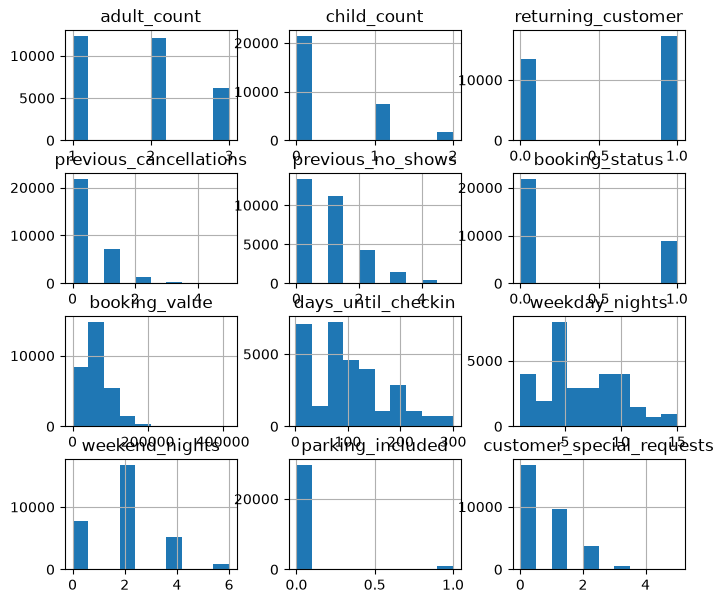

In [18]:
plot_cat_num_target(df_bookings, type_f = 'Num', figsize=(8, 7), ncols=3)

In [19]:
df_bookings[df_bookings['booking_value'] <= 0]

,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
11,INN00011,2021-11-04,онлайн_бронирование,2,0,1,0,1,0,0.0,3,1,0,тип_питания_1,0,тип_1,1
105,INN00105,2019-07-19,офлайн_бронирование,2,0,0,0,0,1,0.0,67,6,2,тип_питания_1,0,тип_1,1
133,INN00133,2021-12-13,корпоративное_бронирование,2,0,1,0,1,0,0.0,77,6,2,тип_питания_1,0,тип_1,3
143,INN00143,2020-05-15,офлайн_бронирование,3,0,0,0,0,1,0.0,157,1,0,тип_питания_1,1,тип_1,0
145,INN00145,2019-03-06,офлайн_бронирование,1,0,0,0,0,0,0.0,7,3,0,тип_питания_1,0,тип_1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30570,INN30570,2020-10-24,офлайн_бронирование,3,0,0,1,0,0,0.0,34,15,6,тип_питания_1,0,тип_1,0
30700,INN30700,2018-10-24,офлайн_бронирование,2,0,0,0,0,1,0.0,63,7,2,тип_питания_1,0,тип_1,0
30710,INN30710,2017-10-01,онлайн_бронирование,2,0,0,0,0,0,0.0,122,10,4,тип_питания_1,0,тип_1,1
30713,INN30713,2018-12-11,онлайн_бронирование,3,1,1,0,1,0,0.0,145,6,2,тип_питания_1,0,тип_1,0


Есть строки с нулевой стоимостью. Каких-то дополнительных проблем в них не замечено, кроме того что значения стоимости бронирования равно нулю для них. Наверное, стоит их удалить из датафрейма, хотя их достаточно много.

In [20]:
df_bookings = df_bookings[df_bookings['booking_value'] > 0].copy().reset_index(drop=True)

In [21]:
df_bookings.describe().T

,count,mean,min,25%,50%,75%,max,std
booking_date,29504,2019-07-15 14:03:02,2017-01-01 00:00:00,2018-06-11 00:00:00,2019-07-03 00:00:00,2020-07-07 00:00:00,2025-10-22 00:00:00,NaN
adult_count,29504.0,1.800942,1.0,1.0,2.0,2.0,3.0,0.751681
child_count,29504.0,0.357409,0.0,0.0,0.0,1.0,2.0,0.585042
returning_customer,29504.0,0.56433,0.0,0.0,1.0,1.0,1.0,0.495853
previous_cancellations,29504.0,0.357646,0.0,0.0,0.0,1.0,5.0,0.629364
previous_no_shows,29504.0,0.840733,0.0,0.0,1.0,1.0,5.0,0.933156
booking_status,29504.0,0.287825,0.0,0.0,0.0,1.0,1.0,0.452757
booking_value,29504.0,64248.436849,6700.0,46900.0,60300.0,89000.0,417221.2,41683.137007
days_until_checkin,29504.0,100.541994,2.0,45.0,90.0,144.0,300.0,71.926833
weekday_nights,29504.0,6.534063,1.0,5.0,6.0,9.0,15.0,3.338803


Других проблем не заметно.

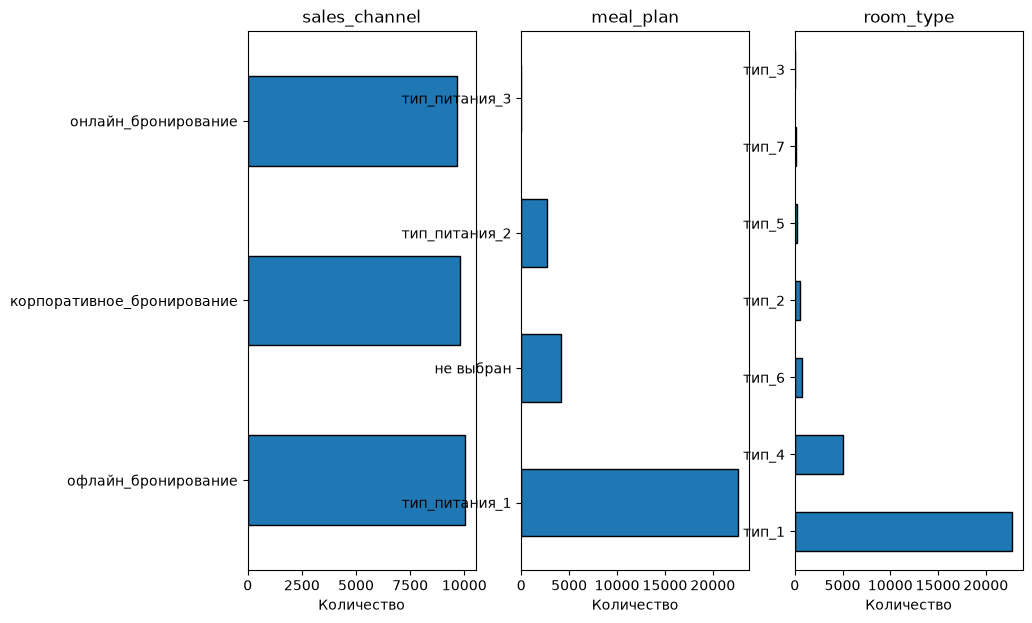

In [22]:
plot_cat_num_target(df_bookings, type_f = 'Cat', exclude_cols=['booking_id','booking_date'], figsize=(10, 7), ncols=3)

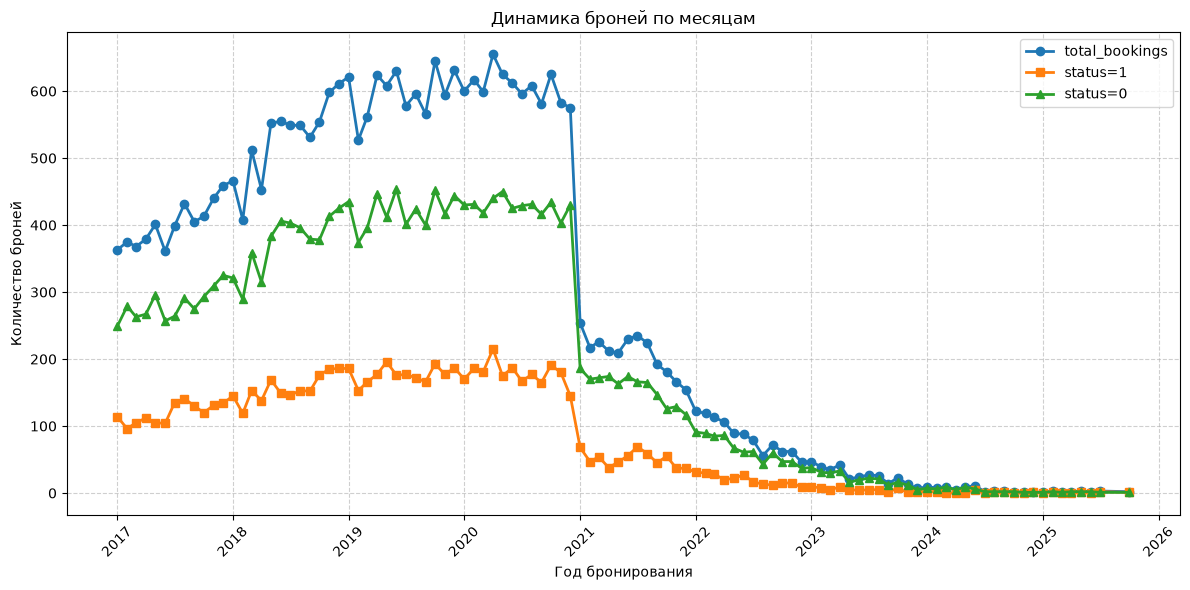

In [23]:
df_monthly = df_bookings.assign(booking_year_month = df_bookings['booking_date'].dt.to_period('M'),
                                booking_1 = (df_bookings['booking_status'] == 1).astype(int),
                                booking_0 = (df_bookings['booking_status'] == 0).astype(int),
                               ).groupby('booking_year_month', as_index=False).agg(total_bookings = ('booking_id', 'count'),
                                                                                   booking_1      = ('booking_1', 'sum'),
                                                                                   booking_0      = ('booking_0', 'sum'))

x = df_monthly['booking_year_month'].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(x, df_monthly['total_bookings'], marker='o', linewidth=2, label='total_bookings')
ax.plot(x, df_monthly['booking_1'],      marker='s', linewidth=2, label='status=1')
ax.plot(x, df_monthly['booking_0'],      marker='^', linewidth=2, label='status=0')

ax.set_xlabel('Год бронирования')
ax.set_ylabel('Количество броней')
ax.set_title('Динамика броней по месяцам')

plt.xticks(rotation=45)

ax.grid(True, linestyle='--', alpha=0.6)
ax.legend()

plt.tight_layout()
plt.show()

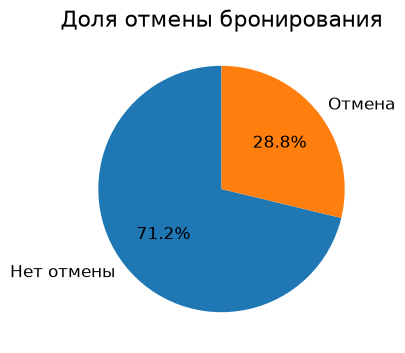

In [24]:
grouped = df_bookings.groupby('booking_status').agg(Share = ('booking_id','count')).sort_values(by = 'Share',ascending=False)
grouped.index = ['Нет отмены' , 'Отмена']
grouped['Share'] = round(100*grouped['Share']/sum(grouped['Share']),2)

fig = grouped['Share'].plot.pie(figsize = (4,4),autopct='%1.1f%%', startangle=90, textprops={'fontsize': 12, 'color': 'black'})

plt.title('Доля отмены бронирования', fontsize=16)
plt.ylabel('')
plt.show()

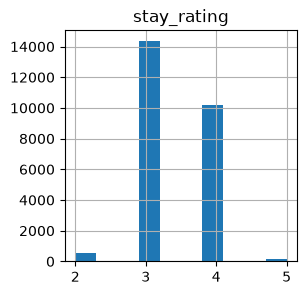

In [25]:
plot_cat_num_target(df_reviews, type_f = 'Num', figsize=(3, 3), ncols=1)

**Выводы**

В распределении большинства признаков не заметно наличия аномалий. В целом признаки характеризуются:
1. `booking_id` (таблица с бронированием) - после удаления дубликатов уникально для каждой брони.
2. `booking_date` - данные представлены c 01.01.2017 по 22.10.2025. В рамках бронирования по месяцам заметно падение количества бронирований начиная с 2021 года. Количество бронирований упало более чем в двое, что может сказаться на качестве модели в последние месяца. Аномалий в распределении целевой переменной в зависимости от времени не заметно.
3. `sales_channel` - аномалий не заметно. Распределение практически равномерное по разным каналам бронирования.
4. `adult_count` - в большинстве случаев люди бронируют для одного или двух человек. В меньшей степени для 3 человек.
5. `child_count` - в болишинстве случаев люди приезжают без детей, в меньшей степени с 1 ребенком и совсем редко с 2.
6. `returning_customer` - большие половины случаев бронирование - бронирования от постоянных клиентов. В меньшей степени - первичное бронирование (около 40%).
7. `previous_cancellations` - в большинстве случаев повторной отмены не было, реже 1 раз. Более одного раза - редкое событие.
8. `previous_no_shows` - сколько раз клиент бронировал и заселялся ранее при текущей брони. Заметно, что в основном клиенты не заселялись ранее, что согласуется с распределением `returning_customer`. Следующая группа - один возврат и так далее.
9. `booking_status` - целевая переменная. Присутствует дисбаланс классов (отмены бронирования, положительный класс - около 28.8%). Возможно, требуется выравнивание классов.
10. `booking_value` - присутствует скос вправо по распределению, что типично для расходов/доходов. Сильных выбрасов нет. Были отмечены нулевые значения в столбце и удалены строки с ними. Их было достаточно много (1229). Для не древесных моделей можно применить процедуру выравнивания (через корень) и масштабирования в pipeline.
11. `days_until_checkin` - похожая ситуация как и в случае с `booking_value`. Для не древесных моделей необходима процедуру выравнивания (через корень) и масштабирования в pipeline.
12. `weekday_nights`, `weekend_nights` - распределения почти нормальные с небольшим скосом вправо.
13. `meal_plan` - в большинстве случаев используется тип_питания_1, гораздо менее популярный вариант - не_выбран. Остальные типы питаний почти не испольуются.
14. `parking_included` - признак редкий, почти никто не бронирует парковку заранее. Вряд-ли будет полезен для модели.
15. `room_type` - почти всегда используется тип_комнаты_1 или тип_комнаты_4. Остальные типы редкие.
16. `customer_special_requests` - в подавляющем большинстве случае особых запросов нет или он единичный. Гораздо реже 2 и более.
17. `stay_rating` - в большинстве случаев рейтинг 3 или 4. Реже 2 и совсем редко 5, что, возможно, говорит о некоторых проблемах с проживанием и обслуживанием клиентов в отели. Почти все находят недостатки в проживании.

<a id='p5b'></a>

---

### Объединение таблиц и создание новых признаков

[К Содержимому проекта](#contents)

При объединении таблиц отзывов с таблицей бронирования стоит придерживаться правила:
- Для каждой даты бронирования в столбце `booking_date` нужно взять комментарий и оценку клиента по предыдущей ближайшей дате отзывов, указанной в столбце `review_date`. Это позволит избежать временной утечки.

В итоговом виде соединять можно двумя путями: 
1. Идея первого пути подтянуть для конкретной брони наиболее близкий по дате отзыв клиента, который и совершил данную бронь. Фактически восстанавливаем `customer_id` в таблице с бронированием. Для этого выполняем следующие шаги:
    * Группируем по `review_date` и `customer_id` таблицу с отзывами. При этом в данном разрезе для `stay_rating` вычислить среднее, а для `review_text` просто конкатенацию строк выполнить. Такая группировка применяется потому, что в таблице с отзывами есть строки от одного клиента на одну дату. 
    * Выделяем уникальные пары `customer_id`,`booking_id` и объединяем (используя внешнее соединение) их с таблицей броней. Таким образом мы сохранили брони без отзывов, но восстановили `customer_id` там, где это возможно.
    * Таблицу из второго шага объединяем (опять используя внешнее соединение) с таблицей из первого шага. Условия соединения - равенсто `customer_id` и `review_date` < `booking_date`. Если строк получится несколько для одной `booking_id`, то берем с максимальной `review_date`.
    * Столбцы `stay_rating` и `review_text` переименовываем в `client_previous_rating`, `client_previous_review`. Пропуски в столбце `client_previous_review` заполняем 'ААААААтсутствуетОтзывml' (такое значение вряд ли встретится при кодировании отзывов). Столбец `client_previous_rating` пока оставим с пропуском. Для древесных моделей этот пропуск можно заполнить флагом -1. Для линейной регрессии лучше заполнить медианой. В последнем случае замена возможна только после разделения на выборки. 
    * Преимущество данного подхода состоит в том, что мы учитываем отзыв только самого клиента, а не мнение какого-то другого человека.
    * Проблема подхода состоит в том, что отзыв клиента мог сильно устареть к текущему моменту и он уже не актуален для него. Кроме того, если он не оставил в другие разы отзыв, то мы не сможем для него восстановить `customer_id` для его броней из таблице с бронированием, а значит подтянуть данные из них. Восстановление возможно, только если клиент несколько раз оставлял отзыв.
    * В предлагаемой витрине по отзывам и брони не получается восстановить значения `customer_id` в таблице с бронированием, хотя по ней заметна применения агрегации по этому столбцу. Зачем было выполнять его удаление не ясно, но имеем, что имеем.
2. Для борьбы с частью недостатков первого подхода выполним еще одно объединение. Его алгоритм в следующем:
    * Группируем по `review_date` таблицу с отзывами. При этом в данном разрезе для `stay_rating` вычисляем среднее, а для `review_text` просто конкатенацию строк выполняем.
    * Используя внешнее соединение объединяем строки таблицы с бронированием с таблицей, полученной на предыдущем шаге. При объединении используем следующее условие: `review_date` < `booking_date` и `review_date` максимальное из возможных.
    * Столбцы `stay_rating` и `review_text` переименовываем в `previous_rating`, `previous_review`.
    * Преимущество данного подхода состоит в том, что мы учитываем ближайший общий фон на момент бронирования. Данную информацию пользователь сам мог видеть при бронировании комнаты.
    * Недостаток состоит в том, что мы не можем точно понять какие именно отзывы смотрел пользователь и на какие именно он обратил свое внимание. Мы учитываем лишь последние отзывы, а не самые популярные.
    
После объединения опишем дополнительную процедуру, которая создает новые признаки и удаляет лишние, не используемые далее в рамках обучения моделей.

In [26]:
def join_tables(df_bookings, df_reviews):
    # По клиенту и дате
    reviews_by_customer = df_reviews.groupby(['customer_id', 'review_date'], as_index=False).agg( 
        stay_rating=('stay_rating', 'mean'),
        review_text=('review_text', lambda s: ' '.join(s.astype(str))))
    
    review_pairs = df_reviews[['customer_id', 'booking_id']].drop_duplicates(subset='booking_id')
    
    bookings_with_customer = df_bookings.merge( review_pairs, on='booking_id', how='left')
    
    reviews_by_customer = reviews_by_customer.sort_values('review_date').reset_index(drop=True)
    bookings_with_customer = bookings_with_customer.sort_values('booking_date').reset_index(drop=True)
    
    result = pd.merge_asof(bookings_with_customer, reviews_by_customer, left_on='booking_date', right_on='review_date',
                           by='customer_id', direction='backward', allow_exact_matches=False)
    result['review_text'] = result['review_text'].fillna('ААААААтсутствуетОтзывml')
    
    result = result.rename(columns={'review_date': 'client_previous_review_date',
                                    'stay_rating': 'client_previous_rating',
                                    'review_text': 'client_previous_review'})
    
    # По дате
    reviews_by_date = df_reviews.groupby('review_date', as_index=False).agg(
        stay_rating=('stay_rating', 'mean'),
        review_text=('review_text', lambda s: ' '.join(s.astype(str))))
    
    
    reviews_by_date = reviews_by_date.sort_values('review_date').reset_index(drop=True)
    result = result.sort_values('booking_date').reset_index(drop=True)
    
    result_fin = pd.merge_asof(result, reviews_by_date, left_on='booking_date', right_on='review_date', 
                               direction='backward', allow_exact_matches=False)
    
    result_fin = result_fin.rename(columns={'review_date': 'last_review_date', 'stay_rating': 'previous_rating',
                                            'review_text': 'previous_review'})
    result_fin['previous_review'] = result_fin['previous_review'].fillna('ААААААтсутствуетОтзывml')
    return result_fin

In [27]:
df = join_tables(df_bookings, df_reviews)

In [28]:
df_reviews[df_reviews['review_date'] < '2017-01-23']

,customer_id,booking_id,review_date,stay_rating,review_text
256,C0190,INN00349,2017-01-21,3,"Неплохо. отличная шумоизоляция, но тесные номе..."
669,C0521,INN00939,2017-01-21,3,"Неплохо. приветливые официанты, но старые номе..."
9224,C6883,INN12916,2017-01-17,4,Отличный отель! разнообразное меню в ресторане...
21413,C16089,INN30039,2017-01-22,4,Отличный отель! профессиональное обслуживание....


In [29]:
df.loc[(df['booking_date']<'2017-01-23') & (df['booking_date']>'2017-01-17'),
       ['booking_id', 'booking_date', 'last_review_date', 'previous_rating', 'previous_review', 
        'client_previous_review_date', 'client_previous_rating', 'client_previous_review']]

,booking_id,booking_date,last_review_date,previous_rating,previous_review,client_previous_review_date,client_previous_rating,client_previous_review
185,INN06540,2017-01-18,2017-01-17,4.0,Отличный отель! разнообразное меню в ресторане...,NaT,NaN,ААААААтсутствуетОтзывml
186,INN14020,2017-01-18,2017-01-17,4.0,Отличный отель! разнообразное меню в ресторане...,NaT,NaN,ААААААтсутствуетОтзывml
187,INN10789,2017-01-18,2017-01-17,4.0,Отличный отель! разнообразное меню в ресторане...,NaT,NaN,ААААААтсутствуетОтзывml
188,INN13459,2017-01-18,2017-01-17,4.0,Отличный отель! разнообразное меню в ресторане...,NaT,NaN,ААААААтсутствуетОтзывml
189,INN24517,2017-01-18,2017-01-17,4.0,Отличный отель! разнообразное меню в ресторане...,NaT,NaN,ААААААтсутствуетОтзывml
190,INN24064,2017-01-18,2017-01-17,4.0,Отличный отель! разнообразное меню в ресторане...,NaT,NaN,ААААААтсутствуетОтзывml
191,INN02970,2017-01-19,2017-01-17,4.0,Отличный отель! разнообразное меню в ресторане...,NaT,NaN,ААААААтсутствуетОтзывml
192,INN17873,2017-01-19,2017-01-17,4.0,Отличный отель! разнообразное меню в ресторане...,NaT,NaN,ААААААтсутствуетОтзывml
193,INN03227,2017-01-19,2017-01-17,4.0,Отличный отель! разнообразное меню в ресторане...,NaT,NaN,ААААААтсутствуетОтзывml
194,INN18751,2017-01-19,2017-01-17,4.0,Отличный отель! разнообразное меню в ресторане...,NaT,NaN,ААААААтсутствуетОтзывml


In [30]:
df.iloc[234,23]

'Неплохо. отличная шумоизоляция, но тесные номера. Для детей ничего нет, им было скучно. В номерах холодно. второго одеяла пришлось выпрашивать Неплохо. приветливые официанты, но старые номера. В номерах холодно. второго одеяла пришлось выпрашивать'

Объединение прошло успешно. В рамках feature engineering планируется создать следующие признаки:
1. `booking_month_sn`, `booking_month_cs` - месяц бронирования, закодированный через синус и косинус по формуле: `booking_month_sn` = $\sin(2\pi\text{ booking_month }/12)$ и `booking_month_cs` = $\cos(2\pi\text{ booking_month }/12)$. Здесь `booking_month` - номер месяца бронирования. За счёт этих столбцов можно учесть сезонность в поведении клиентов. Кодирование именно в таком виде позволяет учесть циклическую смысловую связь между месяцами.
2. `checkin_month_sn`, `checkin_month_cs` - месяц заезда клиента. Рассчитывается как сумма `booking_date` и `days_until_checkin`, затем округляется до месяца и кодируется аналогичным способом, как и `booking_month`.
3. `total_nights` - общая длительность проживания (`weekend_nights + weekday_nights`);
4. `weekend_share`, `weekday_share` - доля выходных и будних в общем количестве дней;
5. `price_per_night` - стоимость одной ночи (`booking_value / total_nights`);
6. `total_guests` - общее количество гостей (`adult_count + child_count`);
7. `price_per_guest` - цена бронирования на одного гостя;
8. Часть лишних признаков, которые не будут использованы далее будут удалены из модели.

Некоторые из приведенных признаков вредны для линейной модели, т.к. линейно зависимы и перед обучением для нее должны быть удалены. Они же для древесных моделей наоборот могут быть полезны. Данные особенности стоит учитывать в pipeline моделей перед обучением.

In [31]:
def feat_builder(df):
    
    df['booking_month'] = df['booking_date'].dt.month
    df['checkin_month'] = (df['booking_date'] + pd.to_timedelta(df['days_until_checkin'], unit='D')).dt.month
    
    df['booking_month_sn'] = np.sin(df['booking_month'] * math.pi / 6)
    df['booking_month_cs'] = np.cos(df['booking_month'] * math.pi / 6)
    df['checkin_month_sn'] = np.sin(df['checkin_month'] * math.pi / 6)
    df['checkin_month_cs'] = np.cos(df['checkin_month'] * math.pi / 6)
    
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    df['weekend_share'] = df['weekend_nights'] / df['total_nights']
    df['weekday_share'] = df['weekday_nights'] / df['total_nights']
    df['price_per_night'] = df['booking_value'] / df['total_nights']
    df['total_guests'] = df['adult_count'] + df['child_count']
    df['price_per_guest'] = df['booking_value'] / df['total_guests']
    
    result = df.drop(columns = ['booking_id', 'booking_date', 'customer_id', 'client_previous_review_date',
                                'last_review_date', 'booking_month', 'checkin_month'])
    return result

In [32]:
df = feat_builder(df)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 29 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   sales_channel              29504 non-null  str    
 1   adult_count                29504 non-null  int64  
 2   child_count                29504 non-null  int64  
 3   returning_customer         29504 non-null  int64  
 4   previous_cancellations     29504 non-null  int64  
 5   previous_no_shows          29504 non-null  int64  
 6   booking_status             29504 non-null  int64  
 7   booking_value              29504 non-null  float64
 8   days_until_checkin         29504 non-null  int64  
 9   weekday_nights             29504 non-null  int64  
 10  weekend_nights             29504 non-null  int64  
 11  meal_plan                  29504 non-null  str    
 12  parking_included           29504 non-null  int64  
 13  room_type                  29504 non-null  str    
 14  c

Создание новых признаков также прошло успешно.

<a id='p5c'></a>

---

### Корреляция

[К Содержимому проекта](#contents)

Для проверки на корреляцию и составления итогового отчета выполним следующее:
- Временно заполним полученные пропуски после объединения флагами для проверки на корреляцию и мультиколлинеарность.
- Тексты отзывов удалим, т.к. для него еще не выполнено кодирование.
- Удалим линенйно зависимые создаваемые принаки перед проверкой на мультиколлинеарность.
- Проанализируем итоговую таблицу.
- Сформулируем общие выводы о данных для моделирования.

In [33]:
def plot_heatmap(data,title,xlabel,ylabel,figsize = (4,4)):
    plt.figure(figsize=figsize)
    fig = sns.heatmap(data,
                      annot=True, # Отображаем численные значения в ячейках карты
                      fmt='.2f', # Форматируем значения корреляции: два знака после точки
                      cmap='coolwarm', # Устанавливаем цветовую гамму от красного (макс. значение) к синему
                      linewidths=0.5, # Форматируем линию между ячейками карты
                      cbar=False # Отключаем цветовую шкалу
                      ,annot_kws={'size': 8}
                      ,mask = np.triu(np.ones_like(data, dtype=bool))
                     )
    plt.title(title, fontsize=14)
    plt.xlabel(xlabel, fontsize=10)
    plt.ylabel(ylabel, fontsize=10)

    fig.tick_params(axis='both', labelsize=8)    
    
    plt.show()

In [34]:
df_copy = df.copy()
df_copy['client_previous_rating'] = df_copy['client_previous_rating'].fillna(-1)
df_copy['previous_rating'] = df_copy['previous_rating'].fillna(-1)

df_copy = df_copy.drop(columns = ['client_previous_review', 'previous_review'])

In [35]:
num_cols = list(df_copy.select_dtypes(include=['int', 'float']).columns)
interval_cols = [col for col in num_cols if col not in ['returning_customer', 'booking_status', 'parking_included',
                                                        'client_previous_rating', 'previous_rating']]
cat_cols = list(df_copy.select_dtypes(include=["object", "string", "category"]).columns)

correlation_matrix_phik = df_copy.phik_matrix(interval_cols = interval_cols)
correlation_matrix_pearson = df_copy[num_cols].corr(method='pearson')
correlation_matrix_spearman = df_copy[num_cols].corr(method='spearman')

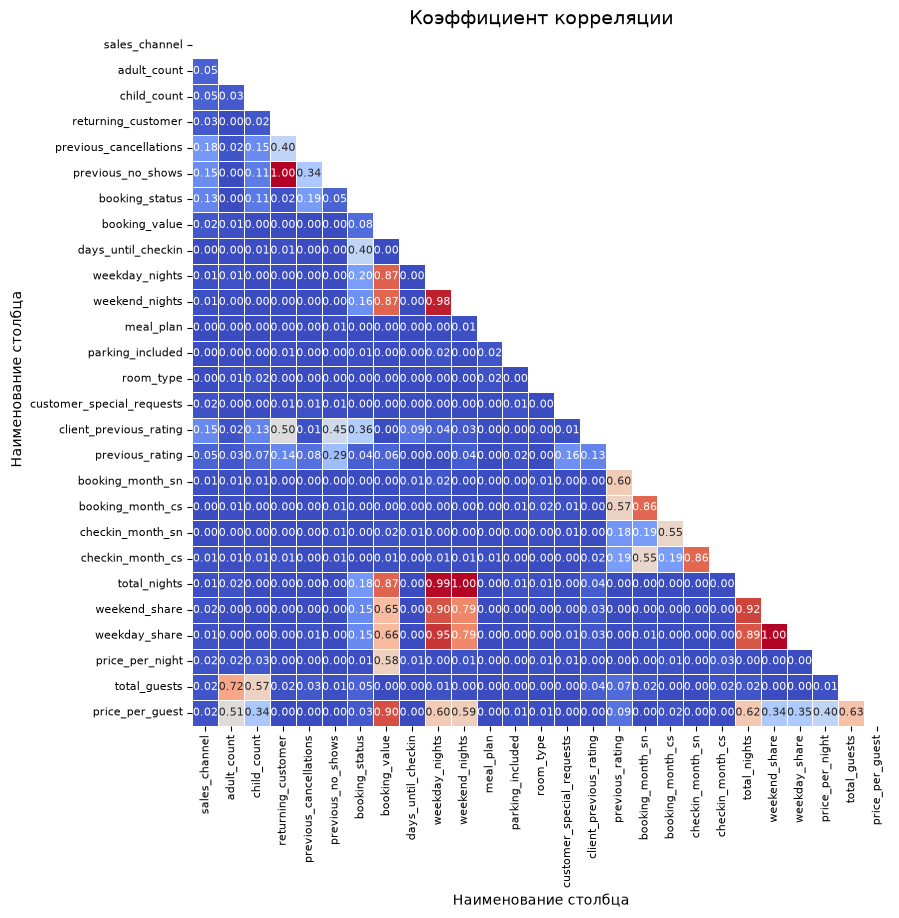

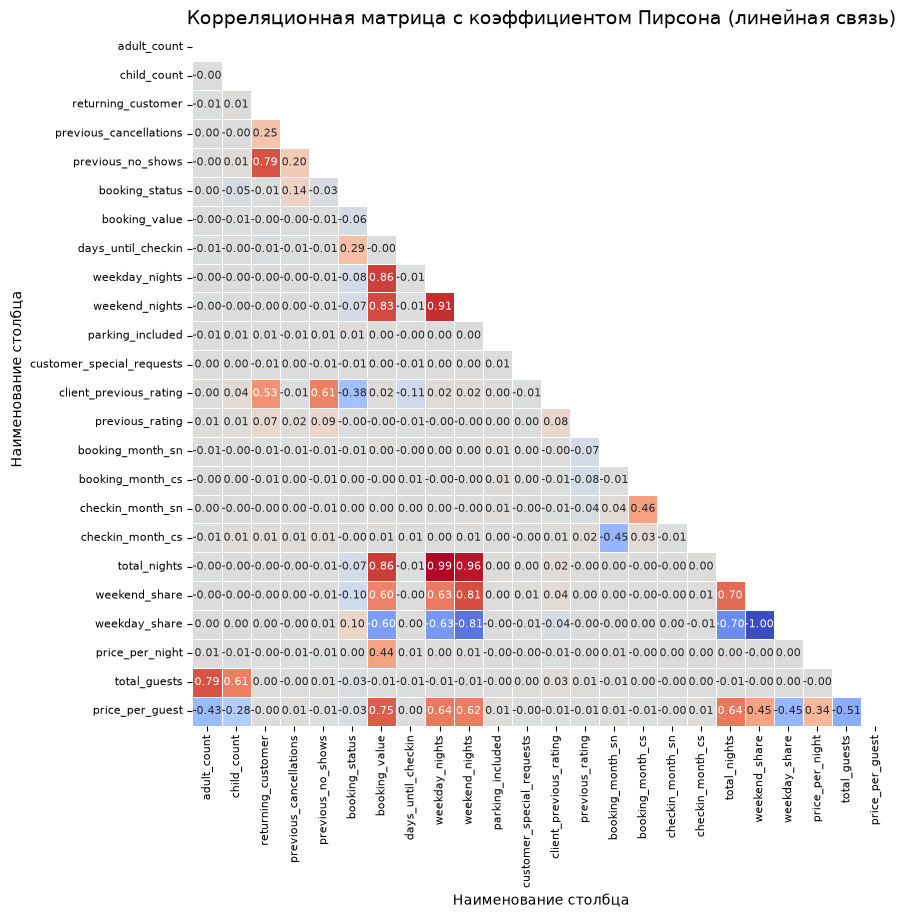

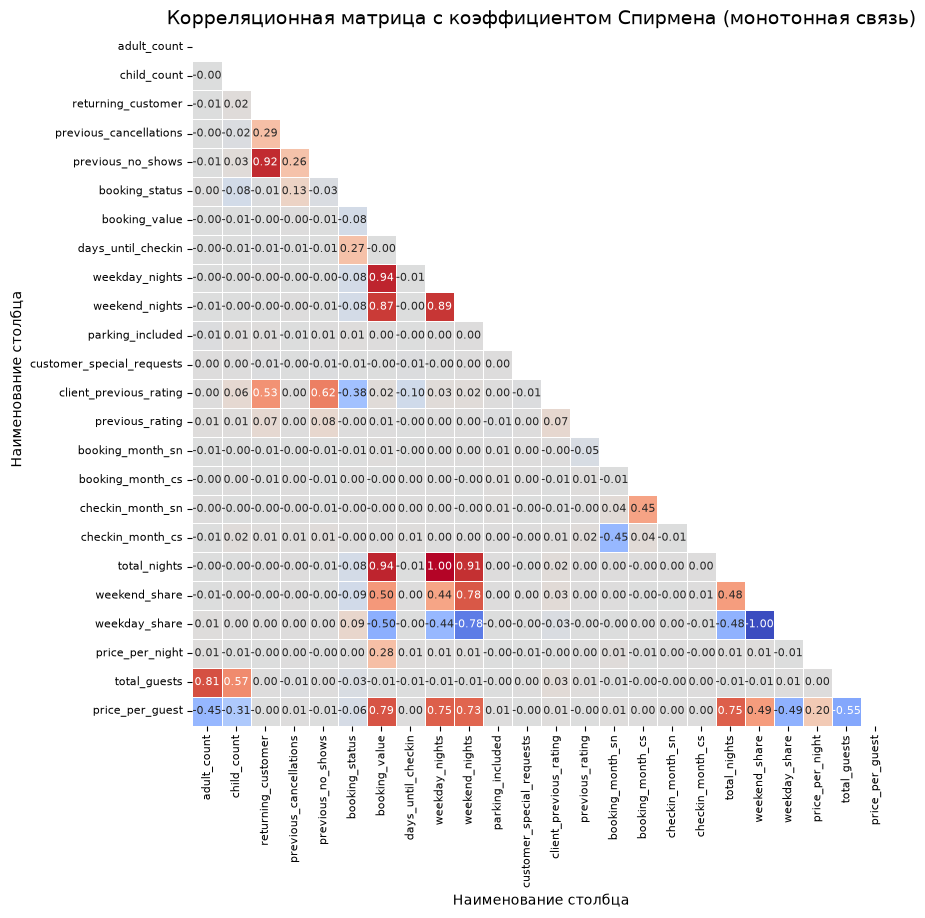

In [36]:
plot_heatmap(correlation_matrix_phik,'Коэффициент корреляции','Наименование столбца'
             ,'Наименование столбца',figsize = (9,9))
plot_heatmap(correlation_matrix_pearson,'Корреляционная матрица с коэффициентом Пирсона (линейная связь)',
             'Наименование столбца','Наименование столбца',figsize = (9,9))
plot_heatmap(correlation_matrix_spearman,'Корреляционная матрица с коэффициентом Спирмена (монотонная связь)',
             'Наименование столбца','Наименование столбца',figsize = (9,9))

Кроме того, проверим на мультиколлинеарность. Для проверки на мультиколлинеарность используется коэффициент variance_inflation_factor (VIF). В рамках данного коэффициент для каждого признака строится регрессия этого признака на все остальные признаки. Если остальные признаки хорошо объясняют его значение, VIF получается большим - это признак мультиколлинеарности.

У VIF есть формула: $ \text{VIF} = \frac{1}{1-R^2_i}$. Здесь $R^2_i$ - коэффициент детерминации при регрессии i-го признака на все остальные признаки.

Традиционно, показатель значения показателя оценивают примерно так: 
- VIF $\approx$ 1 - мультиколлинеарности практически нет
- VIF $\in(1,5)$ допустимый уровень
- VIF $\in[5,10]$ заметная мультиколлинеарность
- VIF > 10 сильная мультиколлинеарность

In [37]:
Xpr = df_copy.drop(columns=['booking_status','total_nights', 'total_guests', 'weekend_share'] + cat_cols).copy()
Xpr = add_constant(Xpr)
vif = pd.DataFrame({
    'feature': Xpr.columns,
    'VIF': [
        variance_inflation_factor(Xpr.values, i)
        for i in range(Xpr.shape[1])
    ]
})
vif = vif.sort_values('VIF', ascending=False)
display(vif)

,feature,VIF
0,const,369.370347
6,booking_value,19.665928
9,weekend_nights,13.962270
8,weekday_nights,13.166885
20,price_per_guest,5.634070
19,price_per_night,4.153858
18,weekday_share,3.606663
5,previous_no_shows,3.102715
3,returning_customer,2.804311
1,adult_count,2.032260


In [38]:
Xpr = df_copy.drop(columns=['booking_status','total_nights', 'total_guests', 'booking_value', 'weekend_share'] + cat_cols).copy()
Xpr = add_constant(Xpr)
vif = pd.DataFrame({
    'feature': Xpr.columns,
    'VIF': [
        variance_inflation_factor(Xpr.values, i)
        for i in range(Xpr.shape[1])
    ]
})
vif = vif.sort_values('VIF', ascending=False)
display(vif)

,feature,VIF
0,const,319.945161
8,weekend_nights,12.926549
7,weekday_nights,8.143093
19,price_per_guest,4.659790
17,weekday_share,3.606456
5,previous_no_shows,3.102698
3,returning_customer,2.804245
1,adult_count,1.857205
11,client_previous_rating,1.694402
18,price_per_night,1.512731


**Выводы по корреляции**

Наиболее сильную попарную связь с целевой переменной демонстрирует `client_previous_rating`, т.е. предыдущая оценка клиента отеля (или отсутствие ее в виде флага -1). Второй по силе признак - `days_until_checkin`. Вероятно, чем больше времени до заселения, тем вероятнее клиент не заселится по итогу. Примерно одинаково на целевую переменную влияют - `weekday_nights`, `total_nights`(количество ночей в будние дни и всего ночей, в меньшей степени `weekend_nights`), `previous_cancellations` - предыдущие отмены. Слабо, но тем не менее связанным оказывается целевая переменная и `sales_channel` (способ оформления), а также `booking_value` (итоговая сумма). `booking_value` достаточно сильно связан с `weekday_nights`, `total_nights`, `weekend_nights`, что заметно как по VIF, так и по $\varphi_k$, что в принципе логично, т.к. сумма заказа должна расти при увеличении количества дней.

К неожиданным связям между признаками можно отнести связь `client_previous_rating` и признаками `sales_channel` и `child_count`, т.е. вероятность оставления клиентом отклика зависит от типа брони и наличия заказа на детей. В данной случае стоит оговорится и напомнить, что связь в том числе может возникнуть с отсутствующим значением рейтинга -1. Также неожиданным является зависимость от `sales_channel` и `child_count` признаков `previous_no_shows` и `previous_cancellations`. В остальном корреляции получилось вполне объяснимыми.

<a id='p5d'></a>

---

### Выводы по EDA

[К Содержимому проекта](#contents)

<span style="font-size: 16px;">**1. Ключевые находки**</span>

В ходе исследовательского анализа данных были изучены две таблицы: `hotel_bookings`, содержащая 35 341 запись о бронированиях, и `hotel_reviews`, включающая 25 177 отзывов о проживании. Целевая переменная `booking_status` является бинарной и отражает факт отмены бронирования. Доля отмен составляет около 28,8%, что указывает на наличие дисбаланса классов. На этапе первичного анализа явных пропусков не обнаружено. При этом выявлены явные дубликаты в таблице `hotel_bookings`, которые были удалены. В таблице `hotel_reviews` явных дубликатов не обнаружено, однако более половины отзывов содержат полностью совпадающий текст. Это может быть связано с особенностями генерации учебных данных. В реальном проекте подобные совпадения потребовали бы дополнительного исследования происхождения отзывов.

Анализ аномалий позволил выявить несколько особенностей данных. В столбце `adult_count` присутствуют явно подозрительные значения 100, 200 и 300, тогда как большинство бронирований оформляется на одного, двух или трёх взрослых. Исходя из анализа значений в этих строказ принято решение разделить `adult_count` на 100 для этих строк. Были выявлены брони с нулевым значением цены бронирования. Таких записей было 1229, они были удалены из таблицы, т.к. считаются явно ошибочными. В столбце `meal_plan` обнаружены разные варианты написания значения 'не выбран', которые необходимо привести к единому формату. Столбцы с датами изначально определяются как строки, поэтому для корректного анализа временных зависимостей их необходимо преобразовать в формат даты.

Временной анализ показал, что бронирования представлены за период с 01.01.2017 по 22.10.2025. Начиная с 2021 года наблюдается снижение количества бронирований более чем в два раза. Это необходимо учитывать при разделении данных на выборки и оценке качества модели: изменение распределения данных во времени может повлиять на способность модели работать с более поздними бронированиями. Распределение большинства признаков соответствует ожидаемому поведению клиентов. Большинство бронирований оформляется на одного или двух взрослых, без детей. Клиенты преимущественно не заказывают парковку заранее, выбирают ограниченное количество типов питания и номеров, а также редко оставляют особые пожелания. 

Анализ взаимосвязей показал, что наиболее сильную попарную связь с целевой переменной демонстрирует `client_previous_rating` - предыдущая оценка отеля самим клиентом. Вторым по силе признаком является `days_until_checkin`, то есть количество дней между оформлением брони и заездом. Также с целевой переменной связаны `weekday_nights`, `total_nights` и `previous_cancellations`. Более слабая связь наблюдается у `sales_channel` и `booking_value`.

При анализе корреляций между самими признаками выявлена ожидаемая зависимость стоимости бронирования `booking_value` от количества ночей проживания. Также обнаружены менее очевидные связи, например между `client_previous_rating`, `sales_channel` и `child_count`. Эти зависимости целесообразно дополнительно проверить на этапе интерпретации модели.

<span style="font-size: 16px;">**2. Создание новых признаков**</span>

В рамках feature engineering были созданы дополнительные признаки, позволяющие учитывать сезонность бронирований, продолжительность проживания и характеристики гостей.

- `booking_month_sn`, `booking_month_cs` - синус и косинус месяца оформления брони. Позволяют учитывать сезонность и циклическую связь между месяцами года.
- `checkin_month_sn`, `checkin_month_cs` - синус и косинус месяца заезда. Характеризуют сезонность спроса на момент предполагаемого заселения.
- `total_nights` - общее количество ночей проживания (`weekday_nights + weekend_nights`). Отражает продолжительность поездки.
- `weekend_share`, `weekday_share` - доля выходных и будних в общем количестве дней.
- `price_per_night` - стоимость одной ночи (`booking_value / total_nights`). Позволяет учитывать стоимость проживания независимо от его продолжительности.
- `total_guests` - общее количество гостей (`adult_count + child_count`). Характеризует размер группы, для которой оформляется бронирование.
- `price_per_guest` - цена бронирования на одного гостя.

Некоторые из приведенных признаков вредны для линейной модели, т.к. линейно зависимы и перед обучением для нее должны быть удалены. Они же для древесных моделей наоборот могут быть полезны. Данные особенности стоит учитывать в pipeline моделей перед обучением.

Дополнительно предусмотрено создание текстовых признаков на основе отзывов. Для этого используются два источника информации: предыдущий отзыв самого клиента (`client_previous_review`) и наиболее актуальный отзыв об отеле на момент бронирования (`previous_review`). Оценки проживания сохраняются в признаках `client_previous_rating` и `previous_rating` соответственно. Текстовые данные планируется преобразовать в числовое представление с помощью векторизации.

При объединении отзывов учитывается только информация, доступная до даты оформления брони. Это позволяет избежать временной утечки и приблизить условия обучения к реальному использованию модели.

Далее для каждого типа моделей будут продуманы свои pipeline по предобработки данных.

<a id='p6a'></a>

---

## Определение лучшей модели

### Предобработка

[К Содержимому проекта](#contents)

Опишем подпрограммы для сбора данных в единый датафрейм. От загрузки из БД до формирования общего датафрейма, пригодного для дальнейшей обработки. Для текстов отзывов проведем предварительную обработку (уберем лишние символы, стоп-слова, преобразуем в леммы). Кроме того, разделим данные на выборки.

In [39]:
# Небольшой тест логики предобработки текстов
def preprocess_text(words_list):
    res_l = [morph.parse(word)[0].normal_form for word in words_list if word not in russian_stopwords]
    return " ".join(res_l)

nltk.download('stopwords', quiet=True)
russian_stopwords = set(stopwords.words("russian")) - set(['не', 'нет', 'хорошо', 'есть'])
morph = pymorphy3.MorphAnalyzer()
df_pr = pd.DataFrame([{'text':'Опишем подпрограммы для сбора данных в единый датафрейм. От загрузки из БД до формирования общего датафрейма, пригодного для дальнейшей обработки.'},
                      {'text':'Для текстов отзывов проведем предварительную обработку (уберем лишние символы, стоп-слова, преобразуем в леммы). Кроме того, разделим данные на выборки.'}])
df_pr['text'] = df_pr['text'].str.replace(r'\W+', ' ', regex=True).str.strip().str.lower().str.split().apply(preprocess_text)
print(df_pr.iloc[0,0] + '\n' + df_pr.iloc[1,0])

описать подпрограмма сбор данные единый датафрейм загрузка бд формирование общий датафрейм пригодный дальнейший обработка
текст отзыв провести предварительный обработка убрать лишний символ стоп слово преобразовать лемма кроме разделить дать выборка


Есть некие проблемы (`данные` преобразуются в `дать`, потому что у слова несколько смыслов и выбирается самый распространенный), но, с другой стороны, до лемматизации `формирования` и `формирование` были двумя разными словами для модели. Теперь это одно и тоже слово для нее.

In [40]:
feature_builder_code = '''import pandas as pd
import numpy as np
import math
import nltk
from nltk.corpus import stopwords
import pymorphy3
from functools import lru_cache # для кэширования лемм

nltk.download('stopwords', quiet=True)
russian_stopwords = set(stopwords.words("russian")) - set(['не', 'нет', 'хорошо', 'есть'])
morph = pymorphy3.MorphAnalyzer()

def Create_join_tables(df_bookings, df_reviews):
    df_bookings['booking_date'] = pd.to_datetime(df_bookings['booking_date'])
    df_bookings['returning_customer'] = df_bookings['returning_customer'].astype('int')
    df_bookings['booking_status'] = (df_bookings['booking_status'] == 'отказ_брони').astype('int')
    df_bookings.loc[df_bookings['meal_plan'] == 'не выбрант', 'meal_plan'] = 'не выбран'
    df_bookings['parking_included'] = df_bookings['parking_included'].astype('int')
    df_bookings.loc[df_bookings['adult_count'] > 99, 'adult_count'] = df_bookings.loc[df_bookings['adult_count'] > 99, 'adult_count']/100
    df_reviews['review_date'] = pd.to_datetime(df_reviews['review_date'])
    df_bookings = df_bookings.drop_duplicates(subset=['booking_id', 'booking_date', 'booking_value', 'booking_status'],
                                              keep='first', ignore_index=True)
    df_bookings = df_bookings[df_bookings['booking_value'] > 0].copy().reset_index(drop=True)
    
    reviews_by_customer = df_reviews.groupby(['customer_id', 'review_date'], as_index=False).agg( 
        stay_rating=('stay_rating', 'mean'),
        review_text=('review_text', lambda s: ' '.join(s.astype(str))))
    
    review_pairs = df_reviews[['customer_id', 'booking_id']].drop_duplicates(subset='booking_id')
    
    bookings_with_customer = df_bookings.merge( review_pairs, on='booking_id', how='left')
    
    reviews_by_customer = reviews_by_customer.sort_values('review_date').reset_index(drop=True)
    bookings_with_customer = bookings_with_customer.sort_values('booking_date').reset_index(drop=True)
    
    result = pd.merge_asof(bookings_with_customer, reviews_by_customer, left_on='booking_date', right_on='review_date',
                           by='customer_id', direction='backward', allow_exact_matches=False)
    result['review_text'] = result['review_text'].fillna('ААААААтсутствуетОтзывml')
    
    result = result.rename(columns={'review_date': 'client_previous_review_date',
                                    'stay_rating': 'client_previous_rating',
                                    'review_text': 'client_previous_review'})
    
    
    reviews_by_date = df_reviews.groupby('review_date', as_index=False).agg(
        stay_rating=('stay_rating', 'mean'),
        review_text=('review_text', lambda s: ' '.join(s.astype(str))))
    
    
    reviews_by_date = reviews_by_date.sort_values('review_date').reset_index(drop=True)
    result = result.sort_values('booking_date').reset_index(drop=True)
    
    df = pd.merge_asof(result, reviews_by_date, left_on='booking_date', right_on='review_date', 
                       direction='backward', allow_exact_matches=False)
    
    df = df.rename(columns={'review_date': 'last_review_date', 'stay_rating': 'previous_rating', 'review_text': 'previous_review'})
    df['previous_review'] = df['previous_review'].fillna('ААААААтсутствуетОтзывml')
    
    df['booking_month'] = df['booking_date'].dt.month
    df['checkin_month'] = (df['booking_date'] + pd.to_timedelta(df['days_until_checkin'], unit='D')).dt.month
    
    df['booking_month_sn'] = np.sin(df['booking_month'] * math.pi / 6)
    df['booking_month_cs'] = np.cos(df['booking_month'] * math.pi / 6)
    df['checkin_month_sn'] = np.sin(df['checkin_month'] * math.pi / 6)
    df['checkin_month_cs'] = np.cos(df['checkin_month'] * math.pi / 6)
    
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    df['weekend_share'] = df['weekend_nights'] / df['total_nights']
    df['weekday_share'] = df['weekday_nights'] / df['total_nights']
    df['price_per_night'] = df['booking_value'] / df['total_nights']
    df['total_guests'] = df['adult_count'] + df['child_count']
    df['price_per_guest'] = df['booking_value'] / df['total_guests']
    
    for col in ['client_previous_review', 'previous_review']:
        s = df[col].str.replace(r'\W+', ' ', regex=True).str.strip().str.lower()
        unique_texts = s.unique()
        
        processed = { text:preprocess_text(text.split()) for text in unique_texts}
        df[col] = s.map(processed)
    
    result = df.drop(columns = ['booking_id', 'customer_id', 'client_previous_review_date',
                                'last_review_date', 'booking_month', 'checkin_month'])
    for col in ['sales_channel', 'meal_plan', 'room_type']:
        result[col] = result[col].astype('category')
    
    return result

@lru_cache(maxsize=100_000)
def lemmatize_word(word):
    return morph.parse(word)[0].normal_form


def preprocess_text(words_list):
    return " ".join(lemmatize_word(word) for word in words_list if word not in russian_stopwords)
'''

# Запись подпрограммы
try:
    feature_builder = "../src/feature_builder.py"
    with open(feature_builder, "w", encoding="utf-8") as f:
        f.write(feature_builder_code)
    
except Exception:
    feature_builder = "feature_builder.py"
    with open(feature_builder, "w", encoding="utf-8") as f:
        f.write(feature_builder_code)

# Считывание подпрограммы
try:
    sys.path.append("../src")
    from feature_builder import Create_join_tables
except Exception:
    from feature_builder import Create_join_tables


# Тест
try:
    df_bookings = pd.read_sql_query(query1, con=engine)
    df_reviews = pd.read_sql_query(query2, con=engine)
except Exception:
    df_reviews = pd.read_csv('./../datasets/hotel_reviews.csv')
    df_bookings = pd.read_csv('./../datasets/hotel_bookings.csv')


df = Create_join_tables(df_bookings, df_reviews)
display(df)
df.info()

,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,...,booking_month_sn,booking_month_cs,checkin_month_sn,checkin_month_cs,total_nights,weekend_share,weekday_share,price_per_night,total_guests,price_per_guest
0,2017-01-01,онлайн_бронирование,3,2,0,0,0,0,67000.0,124,...,0.500000,0.866025,5.000000e-01,-8.660254e-01,10,0.200000,0.800000,6700.0000,5,13400.000000
1,2017-01-01,корпоративное_бронирование,3,0,0,0,0,0,6700.0,63,...,0.500000,0.866025,1.000000e+00,6.123234e-17,1,0.000000,1.000000,6700.0000,3,2233.333333
2,2017-01-01,онлайн_бронирование,2,0,0,0,0,1,166363.4,87,...,0.500000,0.866025,1.000000e+00,6.123234e-17,16,0.250000,0.750000,10397.7125,2,83181.700000
3,2017-01-01,корпоративное_бронирование,1,0,1,1,1,0,46900.0,85,...,0.500000,0.866025,1.000000e+00,6.123234e-17,7,0.285714,0.714286,6700.0000,1,46900.000000
4,2017-01-01,онлайн_бронирование,3,0,1,1,1,1,46900.0,83,...,0.500000,0.866025,1.000000e+00,6.123234e-17,7,0.285714,0.714286,6700.0000,3,15633.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29499,2025-07-01,корпоративное_бронирование,1,0,1,0,4,1,140700.0,7,...,-0.500000,-0.866025,-5.000000e-01,-8.660254e-01,21,0.285714,0.714286,6700.0000,1,140700.000000
29500,2025-07-01,онлайн_бронирование,2,0,1,0,4,1,13400.0,100,...,-0.500000,-0.866025,-8.660254e-01,5.000000e-01,2,0.000000,1.000000,6700.0000,2,6700.000000
29501,2025-07-04,онлайн_бронирование,1,0,1,0,4,0,60300.0,73,...,-0.500000,-0.866025,-1.000000e+00,-1.836970e-16,9,0.222222,0.777778,6700.0000,1,60300.000000
29502,2025-10-02,офлайн_бронирование,1,0,1,0,4,0,46900.0,63,...,-0.866025,0.500000,-2.449294e-16,1.000000e+00,7,0.285714,0.714286,6700.0000,1,46900.000000


<class 'pandas.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype        
---  ------                     --------------  -----        
 0   booking_date               29504 non-null  datetime64[s]
 1   sales_channel              29504 non-null  category     
 2   adult_count                29504 non-null  int64        
 3   child_count                29504 non-null  int64        
 4   returning_customer         29504 non-null  int64        
 5   previous_cancellations     29504 non-null  int64        
 6   previous_no_shows          29504 non-null  int64        
 7   booking_status             29504 non-null  int64        
 8   booking_value              29504 non-null  float64      
 9   days_until_checkin         29504 non-null  int64        
 10  weekday_nights             29504 non-null  int64        
 11  weekend_nights             29504 non-null  int64        
 12  meal_plan                  29

In [41]:
df.iloc[[234,12000],16:20]

,client_previous_rating,client_previous_review,previous_rating,previous_review
234,NaN,аааааатсутствуетотзывml,3.00,неплохо отличный шумоизоляция тесный номер реб...
12000,3.0,неплохо отличный отель не работать телевизор,3.25,неплохо хороший кондиционер старый номер ребён...


In [42]:
df = df.sort_values(by = ['booking_date']).reset_index(drop=True).copy()

n = len(df)
train_val_end_data = df.iloc[int(n * 0.6),0]
cal_end_data = df.iloc[int(n * 0.8),0]

df_train_val = df[df['booking_date'] <= train_val_end_data].reset_index(drop=True).copy()
df_cal       = df[(df['booking_date'] > train_val_end_data) & (df['booking_date'] <= cal_end_data)].reset_index(drop=True).copy()
df_test      = df[df['booking_date'] > cal_end_data].reset_index(drop=True).copy()

print(f"Всего строк: {n}")
for elem in [['df_train_val', df_train_val], ['df_cal', df_cal], ['df_test', df_test]]:
    name = elem[0]
    df_pr = elem[1]
    mindt = df_pr['booking_date'].min()
    maxdt = df_pr['booking_date'].max()
    print(color.BOLD + color.RED+ f"Датафрейм: {name}" + color.END)
    print(f"Количество строк: {df_pr.shape[0]}, что составляет {round(100.0*df_pr.shape[0]/df.shape[0],2)}% от общего числа записей" + color.END)
    print(f"Минимальная дата: {mindt.date()}, максимальная дата {maxdt.date()}")

X_train_val = df_train_val.drop(columns = ['booking_status','booking_date']).copy()
X_cal       = df_cal.drop(columns = ['booking_status','booking_date']).copy()
X_test      = df_test.drop(columns = ['booking_status','booking_date']).copy()

y_train_val = df_train_val['booking_status']
y_cal       = df_cal['booking_status']
y_test      = df_test['booking_status']

Всего строк: 29504
Датафрейм: df_train_val
Количество строк: 17707, что составляет 60.02% от общего числа записей
Минимальная дата: 2017-01-01, максимальная дата 2019-12-01
Датафрейм: df_cal
Количество строк: 5900, что составляет 20.0% от общего числа записей
Минимальная дата: 2019-12-02, максимальная дата 2020-09-20
Датафрейм: df_test
Количество строк: 5897, что составляет 19.99% от общего числа записей
Минимальная дата: 2020-09-21, максимальная дата 2025-10-22


---

Далее опишем пайплайны для трех разновидностей моделей:
- Логистическая регрессия: здесь заполнение пропусков будет реализовано через медиану и кодирование категориальных признаков через OHE. Здесь также проведем масштабирование всех числовых признаков с целью возможно использования при оценке важности признаков.
- Random forest: здесь заполнение пропусков будет выполнено через флаг -1, а для кодирования категориальных признаков будет применен OHE. 
- Модели бустинга: также заполнение пропусков через флаг -1. В случае моделей бустинга используем встроенные механизмы по обработке категорий. Для этого придется написать кастомный ColumnTransformer из-за конфликтов при векторизации отзывов.

Во всех случаях будет применена векторизация для отзывов.

#### Пайплайн для логистической регрессии

In [43]:
# Список с текстовыми столбцами и параметры для TfidfVectorizer
text_list = ['client_previous_review', 'previous_review']
min_df_cl = glob_const.min_df_cl
max_features_cl = glob_const.max_features_cl
min_df_pd = glob_const.min_df_pd
max_features_pd = glob_const.max_features_pd

# Категориальные признаки с малым количеством категорий
ohe_lin = [s for s in X_train_val.select_dtypes(include=["str", "object", "category"]).columns.tolist() 
           if s not in text_list]

# Числовые признаки с масштабированием
num1_lin = [s for s in X_train_val.select_dtypes(include=["float","int"]).columns.tolist()
            if s not in ['client_previous_rating','previous_rating','total_nights','total_guests', 'weekend_share']]
num2_lin = ['client_previous_rating','previous_rating']

num2_pip_lin = Pipeline([('SimpleImputer', SimpleImputer(strategy='median')),
                         ('standard', StandardScaler()) 
                        ])

# ColumnTransformer для всех колонок
LinReg_prep = ColumnTransformer(
    transformers=[('ohe', OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore'), ohe_lin),
                  ('num1', StandardScaler(), num1_lin),
                  ('num2', num2_pip_lin, num2_lin),
                  ('client_previous_review', TfidfVectorizer(ngram_range = (1,2), lowercase = False, 
                                                             min_df = min_df_cl, max_features = max_features_cl), 'client_previous_review'),
                  ('previous_review', TfidfVectorizer(ngram_range = (1,2), lowercase = False,
                                                      min_df = min_df_pd, max_features = max_features_pd), 'previous_review')
                 ],
    remainder='drop') # удаляем линейно-зависимые столбцы 'total_nights','total_guests', для повышения читаемости добавил

#### Пайплайн для Random forest

In [44]:
# Категориальные признаки с малым количеством категорий
ohe_rf = [s for s in X_train_val.select_dtypes(include=["str", "object", "category"]).columns.tolist() 
          if s not in text_list]

# Числовые признаки
num1_rf = [s for s in X_train_val.select_dtypes(include=["float","int"]).columns.tolist()
           if s not in ['client_previous_rating','previous_rating']]
num2_rf = ['client_previous_rating','previous_rating']

# ColumnTransformer для всех колонок
RF_Preprocessor = ColumnTransformer(
    transformers=[('ohe', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), ohe_rf),
                  ('num1', 'passthrough', num1_rf),
                  ('num2', SimpleImputer(strategy='constant', fill_value = -1), num2_rf),
                  ('client_previous_review', TfidfVectorizer(ngram_range = (1,2), lowercase = False, 
                                                             min_df = min_df_cl, max_features = max_features_cl), 'client_previous_review'),
                  ('previous_review', TfidfVectorizer(ngram_range = (1,2), lowercase = False,
                                                      min_df = min_df_pd, max_features = max_features_pd), 'previous_review')
                 ])

#### Пайплайн для моделей бустинга

In [45]:
cat_features = [s for s in X_train_val.select_dtypes(include=["str", "object", "category"]).columns.tolist() 
                if s not in text_list]

class GB_Preprocessor(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        text_list=['client_previous_review', 'previous_review'],
        num_mis_list=['client_previous_rating', 'previous_rating'],
        tfidf_ngram_range=(1, 2),
        lowercase=False,
        fill_value=-1,
        max_features_list = [500, 200],
        min_df_list = [5,3]
    ):
        self.text_list = text_list
        self.num_mis_list = num_mis_list
        self.tfidf_ngram_range = tfidf_ngram_range
        self.lowercase = lowercase
        self.fill_value = fill_value
        self.max_features_list = max_features_list
        self.min_df_list = min_df_list
        
    def fit(self, X, y=None):
        self.text_cols_ = self.text_list
        self.num_mis_ = self.num_mis_list
        self.cat_cols_ = [ col for col in X.select_dtypes(include=["str", "object", "category"]).columns
                          if col not in self.text_cols_]
        self.num_cols_ = [col for col in X.select_dtypes(include=["float", "int", "number"]).columns
                          if col not in self.num_mis_]
        
        self.imputer_ = SimpleImputer(strategy="constant",fill_value=self.fill_value)
        self.imputer_.fit(X[self.num_mis_])
        
        self.vectorizers_ = {}
        for col, max_features, min_df in zip(self.text_cols_, self.max_features_list, self.min_df_list):
            vectorizer = TfidfVectorizer(ngram_range=self.tfidf_ngram_range,
                                         lowercase=self.lowercase, min_df = min_df, max_features = max_features)
            vectorizer.fit(X[col])
            self.vectorizers_[col] = vectorizer
            
        self.tfidf_cols_ = []
        for col in self.text_cols_:
            terms = self.vectorizers_[col].get_feature_names_out()
            self.tfidf_cols_.extend(
                [f"{col}__tfidf_{term}" for term in terms]
            )
        return self

    
    def transform(self, X):
        X_cat = X[self.cat_cols_].copy()
        X_num = X[self.num_cols_].copy()
        X_num_mis = pd.DataFrame(self.imputer_.transform(X[self.num_mis_]),columns=self.num_mis_,index=X.index)
        
        tfidf_frames = []
        for col in self.text_cols_:
            vectorizer = self.vectorizers_[col]
            matrix = vectorizer.transform(X[col])
            terms = vectorizer.get_feature_names_out()
            names = [f"{col}__tfidf_{term}" for term in terms]
            tfidf_df = pd.DataFrame( matrix.toarray(), columns=names, index=X.index)
            tfidf_frames.append(tfidf_df)
        
        X_result = pd.concat([X_cat, X_num, X_num_mis, *tfidf_frames],axis=1)
        return X_result.reindex(columns=self.get_feature_names_out(), fill_value=0)

    def get_feature_names_out(self, input_features=None):
        return self.cat_cols_ + self.num_cols_ + self.num_mis_ + self.tfidf_cols_

GB_prep = GB_Preprocessor(min_df_list = [min_df_cl, min_df_pd], max_features_list = [max_features_cl, max_features_pd])
X_train_val_prep = GB_prep.fit_transform(X_train_val)

print(X_train_val_prep.shape)
display(X_train_val_prep.head())

(17707, 726)


,sales_channel,meal_plan,room_type,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_value,days_until_checkin,...,previous_review__tfidf_холодно,previous_review__tfidf_холодно второй,previous_review__tfidf_хороший,previous_review__tfidf_хороший вид,previous_review__tfidf_хороший кондиционер,previous_review__tfidf_хорошо,previous_review__tfidf_хорошо отапливаться,previous_review__tfidf_чистый,previous_review__tfidf_чистый бассейн,previous_review__tfidf_это
0,онлайн_бронирование,тип_питания_2,тип_2,3,2,0,0,0,67000.0,124,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,корпоративное_бронирование,тип_питания_1,тип_4,3,0,0,0,0,6700.0,63,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,онлайн_бронирование,тип_питания_2,тип_1,2,0,0,0,0,166363.4,87,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,корпоративное_бронирование,тип_питания_1,тип_1,1,0,1,1,1,46900.0,85,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,онлайн_бронирование,тип_питания_1,тип_1,3,0,1,1,1,46900.0,83,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


<a id='p6b'></a>

---

### Кросс-валидация моделей

[К Содержимому проекта](#contents)

В рамках данного раздела опишем: 
1. Подпрограммы для расчета технических и бизнес метрик, а также подпрограмму для кросс-валидации.
2. Pipeline или их аналоги для моделей.
3. Обучение и тестирование моделей с параметрами по умолчанию в рамках кросс-валидации.

#### Расчет метрик

In [46]:
#IR_a
def incremental_revenue_abs(y_true, y_pred, avg_rev = glob_const.AVG_REV, lost_rev = glob_const.LOST_REV, 
                            per_rebook = glob_const.PER_REBOOK, cost_fp = glob_const.COST_FP):
    tot_suc = (y_true == 0).sum()
    tot_can = (y_true == 1).sum()
    ir_b = tot_suc*avg_rev - tot_can*lost_rev
    TN, FP, FN, TP = confusion_matrix(y_true, y_pred).ravel().tolist()
    ir_a = TP*per_rebook + TN*avg_rev - FP*cost_fp - FN*lost_rev
    return ir_a - ir_b
#IR_s
def incremental_revenue_share(y_true, y_pred, avg_rev = glob_const.AVG_REV, lost_rev = glob_const.LOST_REV, 
                              per_rebook = glob_const.PER_REBOOK, cost_fp = glob_const.COST_FP):
    tot_suc = (y_true == 0).sum()
    tot_can = (y_true == 1).sum()
    ir_b = tot_suc*avg_rev - tot_can*lost_rev
    TN, FP, FN, TP = confusion_matrix(y_true, y_pred).ravel().tolist()
    ir_a = TP*per_rebook + TN*avg_rev - FP*cost_fp - FN*lost_rev
    return 100.0*(ir_a - ir_b)/ir_b
#Динамика отказов
def refusal_dynamic_share(y_true, y_pred):
    FN = ((y_true == 1) & (y_pred == 0)).sum()
    share = FN / y_true.sum()
    return 100.0*(1.0 - share)
#Доля ложных отмен
def false_refuse_share(y_true, y_pred):
    FN = ((y_true == 1) & (y_pred == 0)).sum()
    return 100.0*FN/y_true.shape[0]
#Динамика загрузки
def occupancy_dynamic_share(y_true, y_pred):
    TN = ((y_true == 0) & (y_pred == 0)).sum()
    dif = y_true.shape[0] - y_true.sum()
    return 100.0*(1.0 - TN/dif)
#Словарь метрик
def metrics_dict_calc(y_true, y_pred_proba, cutoff = 0.5):
    y_pred = (y_pred_proba >= cutoff).astype(int)
    return {
        'PR_Auc' : average_precision_score(y_true, y_pred_proba),
        'IR_abs_mil' : round(incremental_revenue_abs(y_true, y_pred)*1e-6,2),
        'IR_share' : incremental_revenue_share(y_true, y_pred),
        'Occupancy_Dynamic' : occupancy_dynamic_share(y_true, y_pred),
        'Refusal_Dynamic' : refusal_dynamic_share(y_true, y_pred),
        'False_Refuse_Share' : false_refuse_share(y_true, y_pred),
        'Accuracy' : accuracy_score(y_true, y_pred),
        'Precision' : precision_score(y_true, y_pred),
        'Recall' : recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'Roc_Auc' : roc_auc_score(y_true, y_pred_proba)
    }

Подпрограммы для кросс-валидации

In [47]:
#Программа для кросс-валидации
def TimeSeriesCrossVal(model, X_train_val, y_train_val, row_num = 2000, val_num = 3, model_name = 'Unknown'):
    met_list = ['IR_abs_mil', 'IR_share', 'Refusal_Dynamic', 'Occupancy_Dynamic', 'False_Refuse_Share', 'Accuracy',
                'Precision', 'Recall', 'F1', 'Roc_Auc', 'PR_Auc']
    cv_met = {}
    for met in met_list + ['elapsed']:
        cv_met[f'{met}_tra'] = []
        cv_met[f'{met}_val'] = []
    n = len(y_train_val)
    for i in range(0,val_num):
        val_start = n - (val_num - i) * row_num
        val_end = val_start + row_num

        X_train = X_train_val.iloc[:val_start].copy()
        y_train = y_train_val.iloc[:val_start].copy()

        X_val = X_train_val.iloc[val_start:val_end].copy()
        y_val = y_train_val.iloc[val_start:val_end].copy()
        
        y_pred_proba_train, y_pred_proba_val, elapsed = fit_predict_models(model, X_train, y_train, 
                                                                           X_val, y_val, model_name)
        
        metrics = metrics_dict_calc(y_train, y_pred_proba_train)
        for met in met_list:
            cv_met[f'{met}_tra'].append(metrics[met])
        cv_met['elapsed_tra'].append(elapsed)
        
        metrics = metrics_dict_calc(y_val, y_pred_proba_val)
        for met in met_list:
            cv_met[f'{met}_val'].append(metrics[met])
        cv_met['elapsed_val'].append(elapsed)
    
    cv_met_all = {'model_name': [model_name, model_name], 'fold_name' : ['train', 'val']}
    for met in met_list + ['elapsed']:
        cv_met_all[met] = []
    
    for suf in ['_tra', '_val']:
        for met in met_list + ['elapsed']:
            avg = round(pd.Series(cv_met[met + suf]).mean(),3)
            std = round(pd.Series(cv_met[met + suf]).std(),3)
            
            cv_met_all[met].append(f'{avg} ± {std}')
    
    return cv_met_all

#Тренировка и предсказание разных моделей
def fit_predict_models(model, X_train, y_train, X_val, y_val, model_name, prep_flag = False):
    if ('LogReg' in model_name) or ('RanFor' in model_name):
        start_time = time()
        model.fit(X_train,y_train)
        elapsed_fit = time() - start_time
        
        y_pred_proba_train = model.predict_proba(X_train)[:,1]
        y_pred_proba_val = model.predict_proba(X_val)[:,1]
    else:
        if prep_flag:
            X_train_prep = X_train
            X_val_prep = X_val
        else:
            GB_prep = GB_Preprocessor(min_df_list = [min_df_cl, min_df_pd], max_features_list = [max_features_cl, max_features_pd])
            X_train_prep = GB_prep.fit_transform(X_train, y_train)
            X_val_prep = GB_prep.transform(X_val)
        
        if 'XGBoost' in model_name:
            start_time = time()
            model.fit(X_train_prep, y_train, eval_set=[(X_train_prep, y_train), (X_val_prep, y_val)], verbose=False)
            elapsed_fit = time() - start_time
        elif 'LightGBM' in model_name:
            start_time = time()
            model.fit(X_train_prep, y_train, eval_X=(X_train_prep, X_val_prep), eval_y=(y_train, y_val), 
                  eval_metric="binary_logloss", categorical_feature=cat_features,
                  callbacks=[lgb.early_stopping(stopping_rounds=10, verbose=False), lgb.log_evaluation(period=0)])
            elapsed_fit = time() - start_time
        elif 'CatBoost' in model_name:
            start_time = time()
            model.fit(X_train_prep, y_train, eval_set=[(X_val_prep, y_val)])
            # , cat_features=[]
            elapsed_fit = time() - start_time
        
        y_pred_proba_train = model.predict_proba(X_train_prep)[:,1]
        y_pred_proba_val = model.predict_proba(X_val_prep)[:,1]
        
    return y_pred_proba_train, y_pred_proba_val, elapsed_fit

#### Обучение и кросс-валидация моделей

**Линейная регрессия**

In [48]:
# LogisticRegression
pipelines = {
    'LogReg': Pipeline([('preprocessing', LinReg_prep), 
                        ('model', LogisticRegression(n_jobs=-1, random_state=glob_const.RANDOM_STATE, max_iter = 5000))]),
    'LogReg_balanced': Pipeline([('preprocessing', LinReg_prep), 
                                 ('model', LogisticRegression(n_jobs=-1, random_state=glob_const.RANDOM_STATE, max_iter = 5000, class_weight='balanced'))]),
    'LogReg_over_1': ImbPipeline([('preprocessing', LinReg_prep),
                                  ('over', RandomOverSampler(random_state=glob_const.RANDOM_STATE, sampling_strategy = 1)),
                                  ('model', LogisticRegression(n_jobs=-1, random_state=glob_const.RANDOM_STATE, max_iter = 5000))]),
    'LogReg_over_smote': ImbPipeline([('preprocessing', LinReg_prep),
                                      ('over_smote', SMOTE(random_state=glob_const.RANDOM_STATE)),
                                      ('model', LogisticRegression(n_jobs=-1, random_state=glob_const.RANDOM_STATE, max_iter = 5000))]),
    'LogReg_under_1': ImbPipeline([('preprocessing', LinReg_prep),
                                  ('under', RandomUnderSampler(random_state=glob_const.RANDOM_STATE, sampling_strategy = 1)),
                                  ('model', LogisticRegression(n_jobs=-1, random_state=glob_const.RANDOM_STATE, max_iter = 5000))])
}

lin_df = pd.DataFrame()
for name, model in pipelines.items():
    pr_df = pd.DataFrame(TimeSeriesCrossVal(model, X_train_val, y_train_val, model_name = name))
    lin_df = pd.concat([lin_df, pr_df], axis=0, ignore_index=True)

In [49]:
display(lin_df.sort_values(by = ['fold_name']))

,model_name,fold_name,IR_abs_mil,IR_share,Refusal_Dynamic,Occupancy_Dynamic,False_Refuse_Share,Accuracy,Precision,Recall,F1,Roc_Auc,PR_Auc,elapsed
0,LogReg,train,142.517 ± 22.986,39.489 ± 0.65,45.828 ± 0.526,8.904 ± 0.133,16.045 ± 0.156,0.777 ± 0.002,0.684 ± 0.003,0.458 ± 0.005,0.549 ± 0.005,0.826 ± 0.004,0.677 ± 0.007,5.234 ± 0.733
2,LogReg_balanced,train,145.19 ± 23.348,40.248 ± 1.24,76.127 ± 0.514,28.034 ± 0.287,7.071 ± 0.153,0.732 ± 0.003,0.533 ± 0.004,0.761 ± 0.005,0.627 ± 0.004,0.826 ± 0.004,0.674 ± 0.007,5.14 ± 0.561
4,LogReg_over_1,train,143.12 ± 22.794,39.677 ± 1.09,75.655 ± 0.417,28.028 ± 0.311,7.211 ± 0.129,0.731 ± 0.003,0.532 ± 0.004,0.757 ± 0.004,0.625 ± 0.004,0.826 ± 0.004,0.673 ± 0.007,5.364 ± 1.246
6,LogReg_over_smote,train,143.363 ± 23.602,39.715 ± 0.919,75.827 ± 0.416,28.119 ± 0.202,7.16 ± 0.129,0.73 ± 0.003,0.532 ± 0.003,0.758 ± 0.004,0.625 ± 0.003,0.825 ± 0.004,0.673 ± 0.007,9.394 ± 2.398
8,LogReg_under_1,train,143.297 ± 24.238,39.682 ± 1.133,76.304 ± 0.257,28.444 ± 0.429,7.018 ± 0.071,0.73 ± 0.004,0.53 ± 0.004,0.763 ± 0.003,0.626 ± 0.004,0.824 ± 0.004,0.67 ± 0.008,4.898 ± 0.932
1,LogReg,val,22.97 ± 2.254,43.326 ± 5.484,48.18 ± 0.751,7.972 ± 1.189,15.233 ± 0.284,0.791 ± 0.008,0.716 ± 0.038,0.482 ± 0.008,0.576 ± 0.017,0.853 ± 0.024,0.717 ± 0.042,5.234 ± 0.733
3,LogReg_balanced,val,25.387 ± 5.642,47.982 ± 11.795,76.783 ± 3.121,23.83 ± 2.606,6.817 ± 0.813,0.764 ± 0.027,0.573 ± 0.042,0.768 ± 0.031,0.656 ± 0.039,0.853 ± 0.024,0.715 ± 0.042,5.14 ± 0.561
5,LogReg_over_1,val,25.39 ± 5.757,47.988 ± 11.964,76.17 ± 3.235,23.426 ± 2.946,7.0 ± 0.885,0.764 ± 0.029,0.576 ± 0.045,0.762 ± 0.032,0.656 ± 0.04,0.852 ± 0.024,0.715 ± 0.042,5.364 ± 1.246
7,LogReg_over_smote,val,24.667 ± 5.082,46.598 ± 10.653,76.346 ± 2.633,24.254 ± 2.611,6.95 ± 0.721,0.759 ± 0.025,0.568 ± 0.039,0.763 ± 0.026,0.651 ± 0.034,0.851 ± 0.025,0.713 ± 0.045,9.394 ± 2.398
9,LogReg_under_1,val,24.993 ± 5.675,47.242 ± 11.835,76.729 ± 3.14,24.183 ± 2.687,6.833 ± 0.828,0.761 ± 0.028,0.57 ± 0.043,0.767 ± 0.031,0.654 ± 0.039,0.853 ± 0.025,0.714 ± 0.044,4.898 ± 0.932


Из-за времени счета, а также полученных результатов, далее балансировка классов проводится встроенными методами (`class_weight='balanced'`), а не генерацией наблюдений. Положительный класс составляет около 30% от всех данных, это не сильный дисбаланс между классами. 

**Модели случайного леса**

In [50]:
#Pipeline для перебора:
pipelines = {
    'RanFor': Pipeline([('preprocessing', RF_Preprocessor), 
                        ('model', RandomForestClassifier(n_jobs=-1, random_state=glob_const.RANDOM_STATE))]),
    'RanFor_balanced': Pipeline([('preprocessing', RF_Preprocessor), 
                                 ('model', RandomForestClassifier(n_jobs=-1, random_state=glob_const.RANDOM_STATE, class_weight='balanced'))])
}

rf_df = pd.DataFrame()
for name, model in pipelines.items():
    pr_df = pd.DataFrame(TimeSeriesCrossVal(model, X_train_val, y_train_val, model_name = name))
    rf_df = pd.concat([rf_df, pr_df], axis=0, ignore_index=True)

In [51]:
display(rf_df.sort_values(by = ['fold_name']))

,model_name,fold_name,IR_abs_mil,IR_share,Refusal_Dynamic,Occupancy_Dynamic,False_Refuse_Share,Accuracy,Precision,Recall,F1,Roc_Auc,PR_Auc,elapsed
0,RanFor,train,444.493 ± 64.445,123.352 ± 0.658,100.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,8.949 ± 1.788
2,RanFor_balanced,train,444.493 ± 64.445,123.352 ± 0.658,100.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,1.0 ± 0.0,9.781 ± 1.973
1,RanFor,val,21.193 ± 2.885,40.0 ± 6.553,40.718 ± 4.429,5.003 ± 1.196,17.417 ± 1.075,0.791 ± 0.007,0.773 ± 0.036,0.407 ± 0.044,0.532 ± 0.039,0.857 ± 0.018,0.705 ± 0.034,8.949 ± 1.788
3,RanFor_balanced,val,20.64 ± 1.909,38.913 ± 4.501,38.713 ± 3.713,4.245 ± 1.297,18.017 ± 1.115,0.79 ± 0.004,0.794 ± 0.043,0.387 ± 0.037,0.519 ± 0.029,0.863 ± 0.015,0.715 ± 0.026,9.781 ± 1.973


**Градиентные бустинги**

In [52]:
scale_pos_weight = glob_const.scale_pos_weight

# Инициализируем XGBoost
xgb_model = XGBClassifier(random_state=glob_const.RANDOM_STATE,
                          enable_categorical=True,
                          tree_method="hist",
                          eval_metric="logloss",
                          early_stopping_rounds=10,
                          n_jobs=-1
                         )
# Инициализируем LightGBM
lgbm_model = lgb.LGBMClassifier(random_state=glob_const.RANDOM_STATE, 
                                n_jobs=-1,
                                verbose=-1)
# Инициализируем CatBoostClassifier
catb_model = CatBoostClassifier(random_state=glob_const.RANDOM_STATE, 
                                thread_count=-1,
                                early_stopping_rounds=10,
                                eval_metric='Logloss',
                                use_best_model=True,
                                cat_features=cat_features,
                                verbose=False
                               )

# Инициализируем XGBoost_bal
xgb_model_bal = XGBClassifier(
    random_state=glob_const.RANDOM_STATE,
    enable_categorical=True,
    eval_metric="logloss",
    tree_method="hist",
    early_stopping_rounds=10,
    n_jobs=-1,
    scale_pos_weight=scale_pos_weight
)

# Инициализируем LightGBM_bal
lgbm_model_bal = lgb.LGBMClassifier(
    random_state=glob_const.RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
    class_weight="balanced"
)

# Инициализируем CatBoost_bal
catb_model_bal = CatBoostClassifier(
    random_state=glob_const.RANDOM_STATE,
    thread_count=-1,
    early_stopping_rounds=10,
    eval_metric="Logloss",
    use_best_model=True,
    cat_features=cat_features,
    verbose=False,
    auto_class_weights="Balanced"
)


#Pipeline для перебора:
pipelines = {
    'XGBoost':xgb_model,
    'XGBoost_balanced':xgb_model_bal,
    'LightGBM':lgbm_model,
    'LightGBM_balanced':lgbm_model_bal,
    'CatBoost':catb_model,
    'CatBoost_balanced':catb_model_bal
}

gb_df = pd.DataFrame()
for name, model in pipelines.items():
    pr_df = pd.DataFrame(TimeSeriesCrossVal(model, X_train_val, y_train_val, model_name = name))
    gb_df = pd.concat([gb_df, pr_df], axis=0, ignore_index=True)

In [53]:
display(gb_df.sort_values(by = ['fold_name']))

,model_name,fold_name,IR_abs_mil,IR_share,Refusal_Dynamic,Occupancy_Dynamic,False_Refuse_Share,Accuracy,Precision,Recall,F1,Roc_Auc,PR_Auc,elapsed
0,XGBoost,train,224.503 ± 31.773,62.435 ± 5.09,59.119 ± 3.725,5.475 ± 0.419,12.109 ± 1.119,0.84 ± 0.014,0.819 ± 0.02,0.591 ± 0.037,0.687 ± 0.032,0.903 ± 0.014,0.819 ± 0.026,3.759 ± 0.785
2,XGBoost_balanced,train,258.783 ± 54.504,72.187 ± 14.258,87.852 ± 3.689,18.891 ± 5.335,3.599 ± 1.098,0.831 ± 0.048,0.665 ± 0.073,0.879 ± 0.037,0.757 ± 0.061,0.927 ± 0.032,0.856 ± 0.056,4.062 ± 1.498
4,LightGBM,train,242.22 ± 41.749,67.054 ± 2.054,62.823 ± 1.439,5.455 ± 0.17,11.011 ± 0.424,0.851 ± 0.005,0.829 ± 0.007,0.628 ± 0.014,0.715 ± 0.012,0.921 ± 0.008,0.842 ± 0.013,1.517 ± 0.311
6,LightGBM_balanced,train,282.51 ± 45.479,78.288 ± 1.541,89.861 ± 0.816,17.01 ± 0.238,3.003 ± 0.242,0.85 ± 0.004,0.69 ± 0.005,0.899 ± 0.008,0.78 ± 0.006,0.943 ± 0.005,0.874 ± 0.01,1.817 ± 0.388
8,CatBoost,train,190.703 ± 34.073,52.74 ± 2.427,51.68 ± 2.231,5.746 ± 0.06,14.313 ± 0.692,0.816 ± 0.007,0.791 ± 0.007,0.517 ± 0.022,0.625 ± 0.018,0.878 ± 0.008,0.772 ± 0.014,8.924 ± 2.282
10,CatBoost_balanced,train,203.42 ± 39.794,56.166 ± 2.759,83.244 ± 0.618,24.302 ± 1.199,4.963 ± 0.192,0.779 ± 0.01,0.591 ± 0.013,0.832 ± 0.006,0.691 ± 0.011,0.885 ± 0.006,0.779 ± 0.011,12.246 ± 2.494
1,XGBoost,val,27.547 ± 2.734,51.964 ± 6.751,54.558 ± 2.491,7.529 ± 0.33,13.35 ± 0.477,0.813 ± 0.008,0.751 ± 0.022,0.546 ± 0.025,0.632 ± 0.024,0.881 ± 0.015,0.769 ± 0.027,3.759 ± 0.785
3,XGBoost_balanced,val,29.653 ± 3.04,55.944 ± 7.341,78.013 ± 3.42,20.361 ± 2.419,6.467 ± 1.041,0.792 ± 0.013,0.615 ± 0.03,0.78 ± 0.034,0.687 ± 0.019,0.882 ± 0.013,0.768 ± 0.02,4.062 ± 1.498
5,LightGBM,val,28.223 ± 2.967,53.245 ± 7.163,56.092 ± 2.323,7.834 ± 0.675,12.9 ± 0.433,0.816 ± 0.009,0.748 ± 0.029,0.561 ± 0.023,0.641 ± 0.026,0.883 ± 0.016,0.77 ± 0.029,1.517 ± 0.311
7,LightGBM_balanced,val,30.253 ± 3.355,57.064 ± 7.793,77.023 ± 1.99,19.164 ± 1.103,6.75 ± 0.5,0.797 ± 0.013,0.626 ± 0.025,0.77 ± 0.02,0.691 ± 0.023,0.884 ± 0.014,0.771 ± 0.027,1.817 ± 0.388


In [54]:
all_df = pd.concat([lin_df, rf_df, gb_df], axis=0)

display(all_df[all_df['fold_name'] == 'val'].sort_values(by = ['IR_share'], ascending = False))

,model_name,fold_name,IR_abs_mil,IR_share,Refusal_Dynamic,Occupancy_Dynamic,False_Refuse_Share,Accuracy,Precision,Recall,F1,Roc_Auc,PR_Auc,elapsed
7,LightGBM_balanced,val,30.253 ± 3.355,57.064 ± 7.793,77.023 ± 1.99,19.164 ± 1.103,6.75 ± 0.5,0.797 ± 0.013,0.626 ± 0.025,0.77 ± 0.02,0.691 ± 0.023,0.884 ± 0.014,0.771 ± 0.027,1.817 ± 0.388
11,CatBoost_balanced,val,29.7 ± 4.888,56.081 ± 10.635,80.401 ± 3.207,21.877 ± 1.801,5.75 ± 0.826,0.788 ± 0.022,0.605 ± 0.034,0.804 ± 0.032,0.69 ± 0.034,0.884 ± 0.018,0.772 ± 0.033,12.246 ± 2.494
3,XGBoost_balanced,val,29.653 ± 3.04,55.944 ± 7.341,78.013 ± 3.42,20.361 ± 2.419,6.467 ± 1.041,0.792 ± 0.013,0.615 ± 0.03,0.78 ± 0.034,0.687 ± 0.019,0.882 ± 0.013,0.768 ± 0.02,4.062 ± 1.498
5,LightGBM,val,28.223 ± 2.967,53.245 ± 7.163,56.092 ± 2.323,7.834 ± 0.675,12.9 ± 0.433,0.816 ± 0.009,0.748 ± 0.029,0.561 ± 0.023,0.641 ± 0.026,0.883 ± 0.016,0.77 ± 0.029,1.517 ± 0.311
1,XGBoost,val,27.547 ± 2.734,51.964 ± 6.751,54.558 ± 2.491,7.529 ± 0.33,13.35 ± 0.477,0.813 ± 0.008,0.751 ± 0.022,0.546 ± 0.025,0.632 ± 0.024,0.881 ± 0.015,0.769 ± 0.027,3.759 ± 0.785
9,CatBoost,val,26.76 ± 3.878,50.524 ± 8.884,50.902 ± 4.54,5.995 ± 0.291,14.417 ± 1.056,0.814 ± 0.013,0.778 ± 0.026,0.509 ± 0.045,0.615 ± 0.041,0.884 ± 0.018,0.771 ± 0.034,8.924 ± 2.282
5,LogReg_over_1,val,25.39 ± 5.757,47.988 ± 11.964,76.17 ± 3.235,23.426 ± 2.946,7.0 ± 0.885,0.764 ± 0.029,0.576 ± 0.045,0.762 ± 0.032,0.656 ± 0.04,0.852 ± 0.024,0.715 ± 0.042,5.364 ± 1.246
3,LogReg_balanced,val,25.387 ± 5.642,47.982 ± 11.795,76.783 ± 3.121,23.83 ± 2.606,6.817 ± 0.813,0.764 ± 0.027,0.573 ± 0.042,0.768 ± 0.031,0.656 ± 0.039,0.853 ± 0.024,0.715 ± 0.042,5.14 ± 0.561
9,LogReg_under_1,val,24.993 ± 5.675,47.242 ± 11.835,76.729 ± 3.14,24.183 ± 2.687,6.833 ± 0.828,0.761 ± 0.028,0.57 ± 0.043,0.767 ± 0.031,0.654 ± 0.039,0.853 ± 0.025,0.714 ± 0.044,4.898 ± 0.932
7,LogReg_over_smote,val,24.667 ± 5.082,46.598 ± 10.653,76.346 ± 2.633,24.254 ± 2.611,6.95 ± 0.721,0.759 ± 0.025,0.568 ± 0.039,0.763 ± 0.026,0.651 ± 0.034,0.851 ± 0.025,0.713 ± 0.045,9.394 ± 2.398


**Выводы:**

1. Встроенные методы балансировки классов улучшают результаты всех разновидностей моделей. Далее подбор гиперпараметров только для сбалансированных моделей осуществляется.
2. Наилучшие результаты по `IR_s` показывают модели бустинга. Далее по эффективности идет линейная модель и в конце модель случайного лес. 
3. Стоит отметить что модель случайного леса явно переобучилась, т.к. на тренировочной выборке идеальные результаты, а не валидационной наблюдается серьезное падение качества.
4. Доминирование моделей бустинга, возможно, указывает на нелинейный характер зависимостей. Случайный лес на дефолтных настройках склонен к переобучению. Для него нужен подбор гиперпараметров, что будет сделано далее.
5. Далее подберем гиперпараметры для модели и оценим признаки, влиющие на результат модели.

<a id='p6c'></a>

---

### Оптимизация гиперпараметров

[К Содержимому проекта](#contents)

Для ускорения поиска параметров расчет метрик для оптимизации будет проводится без кросс-валидации, а просто на единственной валидационной выборке. Приводимые диапазоны параметров достаточно узкие - результат экспериментов вне тетради. Такой подход используется для получения нужных параметров за наименьшее время. Стоит отметить, что отбор параметров осуществляется через максимизацию бизнес-метрики `IR_s`, которая зависит от порога. Для расчета берется стандартный порог - 0.5.

---

#### Линейная регрессия

In [55]:
val_num = 3
row_num = 2000
N_train_val = len(y_train_val)

X_train_list = []
y_train_list = []
X_val_list = []
y_val_list = []
for i in range(0,val_num):
    val_start = N_train_val - (val_num - i) * row_num
    val_end = val_start + row_num
    
    X_train = X_train_val.iloc[:val_start]
    y_train = y_train_val.iloc[:val_start].copy()

    X_val = X_train_val.iloc[val_start:val_end]
    y_val = y_train_val.iloc[val_start:val_end].copy()
    
    X_train_list.append(LinReg_prep.fit_transform(X_train, y_train))
    X_val_list.append(LinReg_prep.transform(X_val))
    
    y_train_list.append(y_train)
    y_val_list.append(y_val)

In [56]:
def objective(trial):
    params = {
        "C": trial.suggest_float("C", 1e-4, 1e1, log=True)
    }
    model = LogisticRegression(n_jobs=-1, random_state=glob_const.RANDOM_STATE, 
                               max_iter = 5000, class_weight = 'balanced', **params)
    
    li = []
    for X_train, y_train, X_val, y_val in zip(X_train_list, y_train_list, X_val_list, y_val_list):
        model.fit(X_train, y_train)
        y_pred = model.predict(X_val)
        li.append(incremental_revenue_share(y_val, y_pred))
    
    return np.mean(li)
    
sampler = optuna.samplers.TPESampler(seed=glob_const.RANDOM_STATE)
study_lr = optuna.create_study(direction="maximize", sampler=sampler)
study_lr.optimize(objective, n_trials=23, show_progress_bar=True)

[I 2026-10-30 07:03:35,542] A new study created in memory with name: no-name-f4998198-3ce3-48df-a49f-2ccbe07da8f2


  0%|          | 0/23 [00:00<?, ?it/s]

[I 2026-10-30 07:03:45,890] Trial 0 finished with value: 45.66238708946984 and parameters: {'C': 0.0074593432857265485}. Best is trial 0 with value: 45.66238708946984.
[I 2026-10-30 07:03:57,538] Trial 1 finished with value: 47.32736397478062 and parameters: {'C': 5.669849511478847}. Best is trial 1 with value: 47.32736397478062.
[I 2026-10-30 07:04:08,776] Trial 2 finished with value: 47.443625212903065 and parameters: {'C': 0.4570563099801455}. Best is trial 2 with value: 47.443625212903065.
[I 2026-10-30 07:04:19,330] Trial 3 finished with value: 47.62260539206867 and parameters: {'C': 0.09846738873614563}. Best is trial 3 with value: 47.62260539206867.
[I 2026-10-30 07:04:28,878] Trial 4 finished with value: 31.269356512119135 and parameters: {'C': 0.0006026889128682511}. Best is trial 3 with value: 47.62260539206867.
[I 2026-10-30 07:04:32,623] Trial 5 finished with value: 31.269356512119135 and parameters: {'C': 0.000602521573620386}. Best is trial 3 with value: 47.62260539206867

Лучшие гиперпараметры: {'C': 0.9802989335981928}
Лучшее значение IR_s: 47.99694232229748


C:\Users\EA\AppData\Local\Temp\ipykernel_14596\3093559337.py:5: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study_lr)
C:\Users\EA\AppData\Local\Temp\ipykernel_14596\3093559337.py:6: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study_lr)


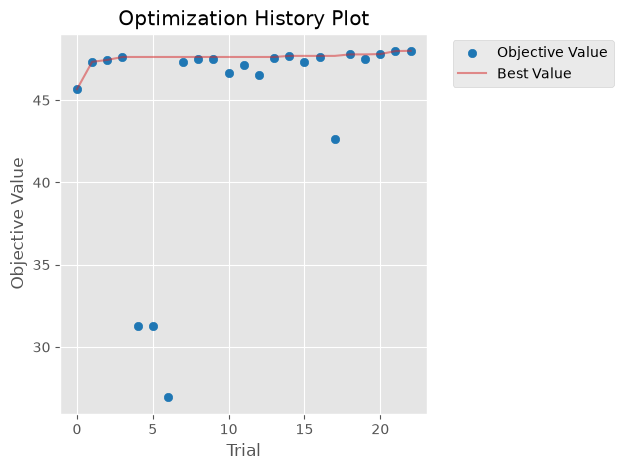

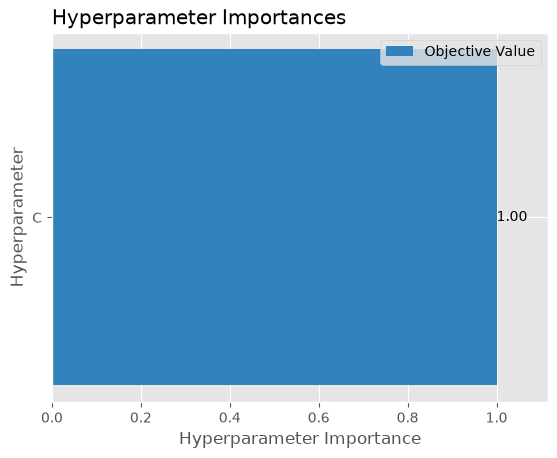

In [57]:
# Лучшие гиперпараметры и качество
print("Лучшие гиперпараметры:", study_lr.best_params)
print("Лучшее значение IR_s:", study_lr.best_value)

plot_optimization_history(study_lr)
plot_param_importances(study_lr)
plt.show()

---

#### Random Forest

In [58]:
X_train_list = []
y_train_list = []
X_val_list = []
y_val_list = []
for i in range(0,val_num):
    val_start = N_train_val - (val_num - i) * row_num
    val_end = val_start + row_num
    
    X_train = X_train_val.iloc[:val_start]
    y_train = y_train_val.iloc[:val_start].copy()

    X_val = X_train_val.iloc[val_start:val_end]
    y_val = y_train_val.iloc[val_start:val_end].copy()
    
    X_train_list.append(RF_Preprocessor.fit_transform(X_train, y_train))
    X_val_list.append(RF_Preprocessor.transform(X_val))
    
    y_train_list.append(y_train)
    y_val_list.append(y_val)

In [59]:
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 40, 120),
        "max_depth": trial.suggest_int("max_depth", 2, 25),
        "max_features": trial.suggest_categorical("max_features", ['sqrt', 'log2']),
        "max_samples": trial.suggest_float("max_samples", 0.5, 0.75)
    }
    
    model = RandomForestClassifier(n_jobs=-1, random_state=glob_const.RANDOM_STATE, class_weight='balanced', **params)
    li = []
    for X_train, y_train, X_val, y_val in zip(X_train_list, y_train_list, X_val_list, y_val_list):
        model.fit(X_train, y_train)
        y_pred = model.predict(X_val)
        li.append(incremental_revenue_share(y_val, y_pred))
    
    return np.mean(li)

sampler = optuna.samplers.TPESampler(seed=glob_const.RANDOM_STATE)
study_rf = optuna.create_study(direction="maximize", sampler=sampler)
study_rf.optimize(objective, n_trials=65, show_progress_bar=True)

[I 2026-10-30 07:05:31,165] A new study created in memory with name: no-name-544f6a11-65b8-4bb5-8834-3101be595b23


  0%|          | 0/65 [00:00<?, ?it/s]

[I 2026-10-30 07:05:37,165] Trial 0 finished with value: 42.26876975107092 and parameters: {'n_estimators': 70, 'max_depth': 24, 'max_features': 'sqrt', 'max_samples': 0.5390046601106091}. Best is trial 0 with value: 42.26876975107092.
[I 2026-10-30 07:05:38,181] Trial 1 finished with value: 5.282296041691057 and parameters: {'n_estimators': 52, 'max_depth': 3, 'max_features': 'sqrt', 'max_samples': 0.6770181444490113}. Best is trial 0 with value: 42.26876975107092.
[I 2026-10-30 07:05:42,178] Trial 2 finished with value: 37.853810578838164 and parameters: {'n_estimators': 41, 'max_depth': 25, 'max_features': 'sqrt', 'max_samples': 0.5454562418017752}. Best is trial 0 with value: 42.26876975107092.
[I 2026-10-30 07:05:43,549] Trial 3 finished with value: 39.76751800738818 and parameters: {'n_estimators': 54, 'max_depth': 9, 'max_features': 'sqrt', 'max_samples': 0.5728072850495105}. Best is trial 0 with value: 42.26876975107092.
[I 2026-10-30 07:05:45,047] Trial 4 finished with value: 

[I 2026-10-30 07:08:05,069] Trial 33 finished with value: 50.79692492494933 and parameters: {'n_estimators': 93, 'max_depth': 15, 'max_features': 'sqrt', 'max_samples': 0.6845834361924437}. Best is trial 17 with value: 51.488574269394796.
[I 2026-10-30 07:08:07,209] Trial 34 finished with value: 42.662207911985384 and parameters: {'n_estimators': 74, 'max_depth': 11, 'max_features': 'sqrt', 'max_samples': 0.7018411843685078}. Best is trial 17 with value: 51.488574269394796.
[I 2026-10-30 07:08:16,407] Trial 35 finished with value: 48.87862430747591 and parameters: {'n_estimators': 109, 'max_depth': 22, 'max_features': 'sqrt', 'max_samples': 0.7384218381437286}. Best is trial 17 with value: 51.488574269394796.
[I 2026-10-30 07:08:20,663] Trial 36 finished with value: 49.14702060777532 and parameters: {'n_estimators': 87, 'max_depth': 15, 'max_features': 'sqrt', 'max_samples': 0.6483485555968106}. Best is trial 17 with value: 51.488574269394796.
[I 2026-10-30 07:08:29,571] Trial 37 finis

Лучшие гиперпараметры: {'n_estimators': 105, 'max_depth': 18, 'max_features': 'sqrt', 'max_samples': 0.7131976755640757}
Лучшее значение IR_s: 52.55784780057667


C:\Users\EA\AppData\Local\Temp\ipykernel_14596\1929222829.py:5: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study_rf)
C:\Users\EA\AppData\Local\Temp\ipykernel_14596\1929222829.py:6: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study_rf)


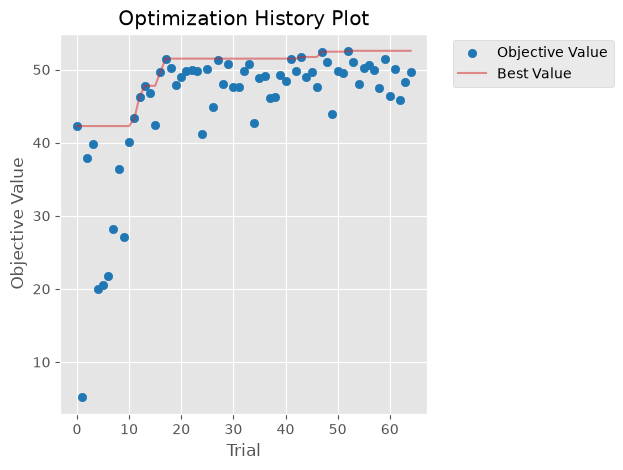

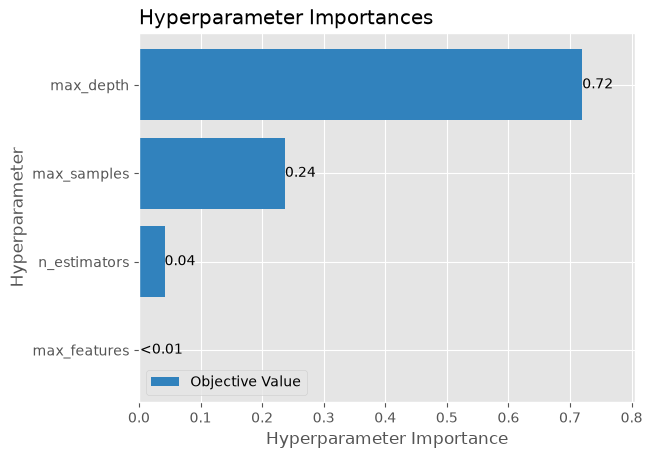

In [60]:
# Лучшие гиперпараметры и качество
print("Лучшие гиперпараметры:", study_rf.best_params)
print("Лучшее значение IR_s:", study_rf.best_value)

plot_optimization_history(study_rf)
plot_param_importances(study_rf)
plt.show()

---

#### XGBoost

In [61]:
X_train_list = []
y_train_list = []
X_val_list = []
y_val_list = []
for i in range(0,val_num):
    val_start = N_train_val - (val_num - i) * row_num
    val_end = val_start + row_num
    
    X_train = X_train_val.iloc[:val_start]
    y_train = y_train_val.iloc[:val_start].copy()

    X_val = X_train_val.iloc[val_start:val_end]
    y_val = y_train_val.iloc[val_start:val_end].copy()
    
    X_train_list.append(GB_prep.fit_transform(X_train, y_train))
    X_val_list.append(GB_prep.transform(X_val))
    
    y_train_list.append(y_train)
    y_val_list.append(y_val)

In [62]:
def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.08, 0.4),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "n_estimators": trial.suggest_int("n_estimators", 40, 150),
        "gamma": trial.suggest_float('gamma', 1e-3, 1, log=True),
        "reg_alpha": trial.suggest_float('reg_alpha', 1e-7, 1e-1, log=True),
        "reg_lambda": trial.suggest_float('reg_lambda', 1e-7, 1e-1, log=True)
    }
    
    model = XGBClassifier(random_state=glob_const.RANDOM_STATE, enable_categorical=True, tree_method="hist",
                          eval_metric="logloss", early_stopping_rounds=10, n_jobs=-1, 
                          scale_pos_weight=scale_pos_weight, **params)
    li = []
    for X_train, y_train, X_val, y_val in zip(X_train_list, y_train_list, X_val_list, y_val_list):
        model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)
        y_pred = model.predict(X_val)
        li.append(incremental_revenue_share(y_val, y_pred))
    
    return np.mean(li)

sampler = optuna.samplers.TPESampler(seed=glob_const.RANDOM_STATE)
study_XGB = optuna.create_study(direction="maximize", sampler=sampler)
study_XGB.optimize(objective, n_trials=25, show_progress_bar=True)

[I 2026-10-30 07:11:17,049] A new study created in memory with name: no-name-f0cd501b-3a66-4a6c-a7a8-7309a9aa792b


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2026-10-30 07:11:32,737] Trial 0 finished with value: 56.30314794538308 and parameters: {'learning_rate': 0.199852838031156, 'max_depth': 6, 'n_estimators': 121, 'gamma': 0.06251373574521749, 'reg_alpha': 8.632008168602531e-07, 'reg_lambda': 8.62913219007186e-07}. Best is trial 0 with value: 56.30314794538308.
[I 2026-10-30 07:11:57,460] Trial 1 finished with value: 56.82154245889367 and parameters: {'learning_rate': 0.09858675589382383, 'max_depth': 6, 'n_estimators': 106, 'gamma': 0.13311216080736885, 'reg_alpha': 1.3289448722869174e-07, 'reg_lambda': 0.06598711072054077}. Best is trial 1 with value: 56.82154245889367.
[I 2026-10-30 07:12:07,083] Trial 2 finished with value: 56.925416153160334 and parameters: {'learning_rate': 0.346381645056135, 'max_depth': 3, 'n_estimators': 60, 'gamma': 0.0035498788321965025, 'reg_alpha': 6.690421166498795e-06, 'reg_lambda': 0.00014077923139972398}. Best is trial 2 with value: 56.925416153160334.
[I 2026-10-30 07:12:21,015] Trial 3 finished wit

Лучшие гиперпараметры: {'learning_rate': 0.14188600512535754, 'max_depth': 6, 'n_estimators': 43, 'gamma': 0.1296383274284048, 'reg_alpha': 3.6206693561208578e-06, 'reg_lambda': 0.0019123666256042487}
Лучшее значение IR_s: 57.437288602716045


C:\Users\EA\AppData\Local\Temp\ipykernel_14596\1789733543.py:5: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study_XGB)
C:\Users\EA\AppData\Local\Temp\ipykernel_14596\1789733543.py:6: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study_XGB)


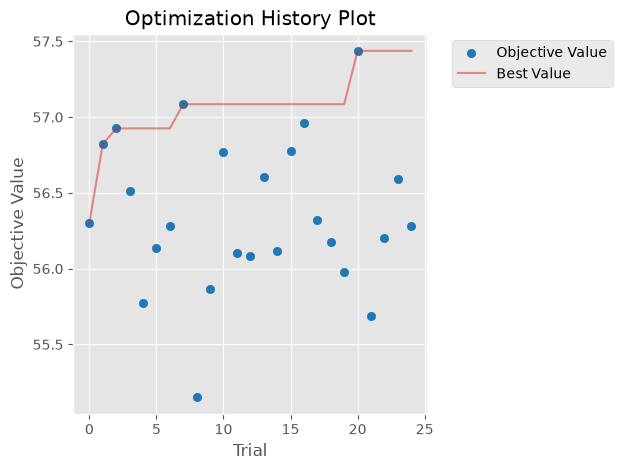

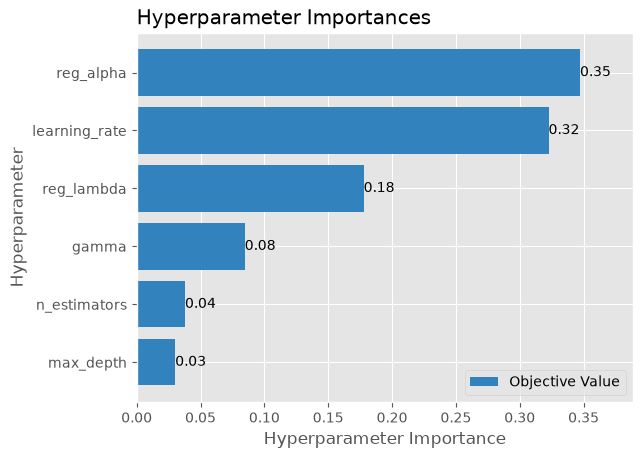

In [63]:
# Лучшие гиперпараметры и качество
print("Лучшие гиперпараметры:", study_XGB.best_params)
print("Лучшее значение IR_s:", study_XGB.best_value)

plot_optimization_history(study_XGB)
plot_param_importances(study_XGB)
plt.show()

---

#### LightGBM

In [64]:
def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.06, 0.4, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "n_estimators": trial.suggest_int("n_estimators", 20, 150),
        "num_leaves": trial.suggest_int('num_leaves', 50, 250),
        "min_child_samples": trial.suggest_int('min_child_samples', 5, 250),
        "reg_alpha": trial.suggest_float('reg_alpha', 1e-7, 10, log=True),
        "reg_lambda": trial.suggest_float('reg_lambda', 1e-7, 10, log=True)
    }
    
    model = lgb.LGBMClassifier(random_state=glob_const.RANDOM_STATE, n_jobs=-1, verbose=-1, class_weight="balanced", **params)
    li = []
    for X_train, y_train, X_val, y_val in zip(X_train_list, y_train_list, X_val_list, y_val_list):
        model.fit(X_train, y_train, eval_X=(X_train, X_val), eval_y=(y_train, y_val), 
                  eval_metric="binary_logloss", categorical_feature=cat_features,
                  callbacks=[lgb.early_stopping(stopping_rounds=10, verbose=False), lgb.log_evaluation(period=0)])
        y_pred = model.predict(X_val)
        li.append(incremental_revenue_share(y_val, y_pred))
    
    return np.mean(li)

sampler = optuna.samplers.TPESampler(seed=glob_const.RANDOM_STATE)
study_LGBM = optuna.create_study(direction="maximize", sampler=sampler)
study_LGBM.optimize(objective, n_trials=11, show_progress_bar=True)

[I 2026-10-30 07:17:29,375] A new study created in memory with name: no-name-fc623a24-4f0e-48d6-aa6c-f508486595dc


  0%|          | 0/11 [00:00<?, ?it/s]

[I 2026-10-30 07:17:33,084] Trial 0 finished with value: 55.824527656447515 and parameters: {'learning_rate': 0.12210631587281769, 'max_depth': 6, 'n_estimators': 115, 'num_leaves': 170, 'min_child_samples': 43, 'reg_alpha': 1.769930294063333e-06, 'reg_lambda': 2.9152036385288277e-07}. Best is trial 0 with value: 55.824527656447515.
[I 2026-10-30 07:17:35,395] Trial 1 finished with value: 55.85368133461956 and parameters: {'learning_rate': 0.3103139847134641, 'max_depth': 5, 'n_estimators': 112, 'num_leaves': 54, 'min_child_samples': 243, 'reg_alpha': 0.45660548734461237, 'reg_lambda': 4.997040685255809e-06}. Best is trial 1 with value: 55.85368133461956.
[I 2026-10-30 07:17:37,725] Trial 2 finished with value: 52.20499213894726 and parameters: {'learning_rate': 0.08471463230820372, 'max_depth': 2, 'n_estimators': 59, 'num_leaves': 155, 'min_child_samples': 111, 'reg_alpha': 2.1371407316372958e-05, 'reg_lambda': 0.007849159562555079}. Best is trial 1 with value: 55.85368133461956.
[I 2

Лучшие гиперпараметры: {'learning_rate': 0.11805474150683114, 'max_depth': 3, 'n_estimators': 91, 'num_leaves': 78, 'min_child_samples': 202, 'reg_alpha': 3.9482545946332436e-07, 'reg_lambda': 7.854083114461327}
Лучшее значение IR_s: 57.48485773881516


C:\Users\EA\AppData\Local\Temp\ipykernel_14596\380654026.py:5: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study_LGBM)
C:\Users\EA\AppData\Local\Temp\ipykernel_14596\380654026.py:6: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study_LGBM)


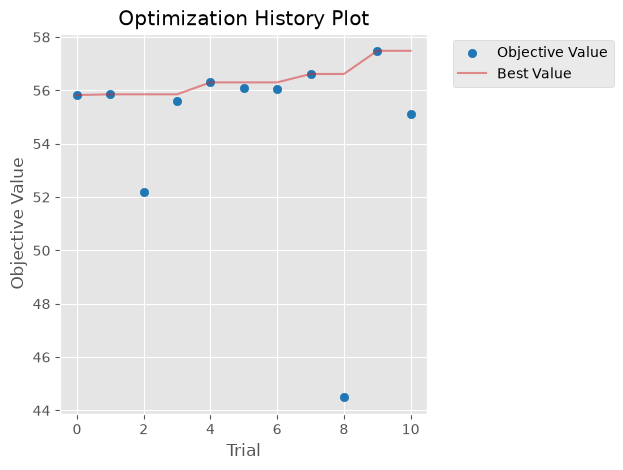

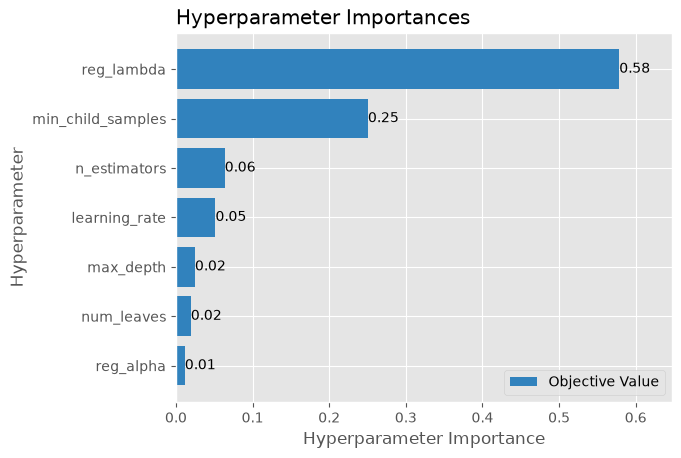

In [65]:
# Лучшие гиперпараметры и качество
print("Лучшие гиперпараметры:", study_LGBM.best_params)
print("Лучшее значение IR_s:", study_LGBM.best_value)

plot_optimization_history(study_LGBM)
plot_param_importances(study_LGBM)
plt.show()

---

#### CatBoost	

In [66]:
def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.1, 0.5, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 5),
        "n_estimators": trial.suggest_int("n_estimators", 50, 250),
        "l2_leaf_reg": trial.suggest_float('l2_leaf_reg', 1e-4, 10, log=True)
    }
    
    model = CatBoostClassifier(random_state=glob_const.RANDOM_STATE, thread_count=-1, early_stopping_rounds=10, 
                               cat_features=cat_features, eval_metric='Logloss', use_best_model=True,
                               verbose=False, auto_class_weights="Balanced", **params)
    li = []
    for X_train, y_train, X_val, y_val in zip(X_train_list, y_train_list, X_val_list, y_val_list):
        model.fit(X_train, y_train, eval_set=[(X_val, y_val)])
        y_pred = model.predict(X_val)
        li.append(incremental_revenue_share(y_val, y_pred))
    
    return np.mean(li)

sampler = optuna.samplers.TPESampler(seed=glob_const.RANDOM_STATE)
study_CatB = optuna.create_study(direction="maximize", sampler=sampler)
study_CatB.optimize(objective, n_trials=20, show_progress_bar=True)

[I 2026-10-30 07:17:59,987] A new study created in memory with name: no-name-30e6d293-5662-4314-bbfc-9c0e72b76295


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-10-30 07:18:18,623] Trial 0 finished with value: 55.63539525749611 and parameters: {'learning_rate': 0.18272261776066237, 'max_depth': 5, 'n_estimators': 197, 'l2_leaf_reg': 0.09846738873614563}. Best is trial 0 with value: 55.63539525749611.
[I 2026-10-30 07:18:27,497] Trial 1 finished with value: 55.50880517880096 and parameters: {'learning_rate': 0.12854415975274447, 'max_depth': 2, 'n_estimators': 61, 'l2_leaf_reg': 2.1423021757741068}. Best is trial 0 with value: 55.63539525749611.
[I 2026-10-30 07:18:36,668] Trial 2 finished with value: 55.987975263846785 and parameters: {'learning_rate': 0.2631245451057451, 'max_depth': 4, 'n_estimators': 54, 'l2_leaf_reg': 7.072114131472227}. Best is trial 2 with value: 55.987975263846785.
[I 2026-10-30 07:18:43,838] Trial 3 finished with value: 55.84416866459273 and parameters: {'learning_rate': 0.3818145165896869, 'max_depth': 2, 'n_estimators': 86, 'l2_leaf_reg': 0.0008260808399079611}. Best is trial 2 with value: 55.987975263846785.

Лучшие гиперпараметры: {'learning_rate': 0.3084887464902941, 'max_depth': 3, 'n_estimators': 198, 'l2_leaf_reg': 0.0036181114348303894}
Лучшее значение IR_s: 57.87388661906132


C:\Users\EA\AppData\Local\Temp\ipykernel_14596\3867803150.py:5: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study_CatB)
C:\Users\EA\AppData\Local\Temp\ipykernel_14596\3867803150.py:6: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study_CatB)


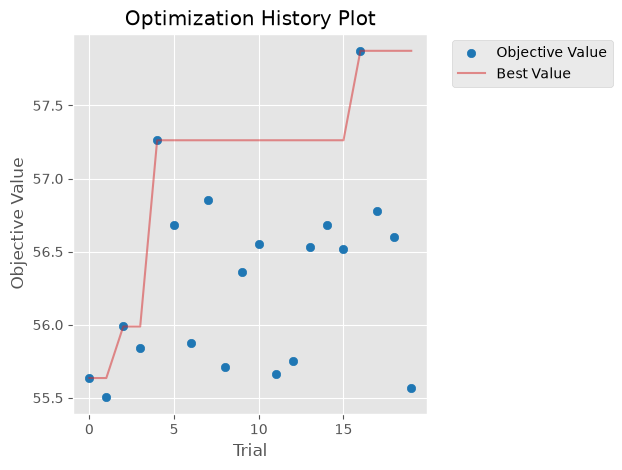

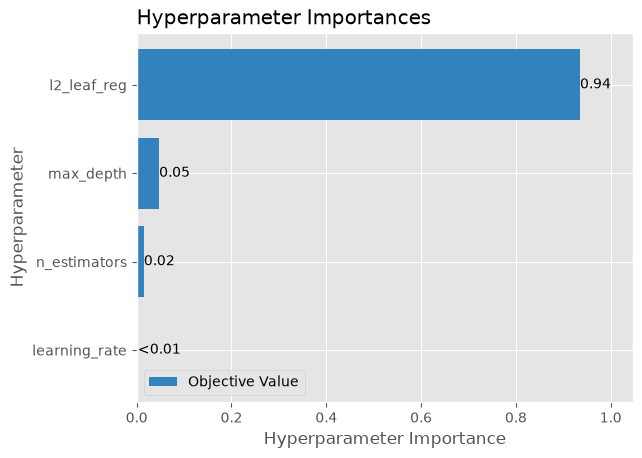

In [67]:
# Лучшие гиперпараметры и качество
print("Лучшие гиперпараметры:", study_CatB.best_params)
print("Лучшее значение IR_s:", study_CatB.best_value)

plot_optimization_history(study_CatB)
plot_param_importances(study_CatB)
plt.show()

<a id='p6d'></a>

---

### Выбор, калибровка модели

[К Содержимому проекта](#contents)

Оценим результаты моделей на стандартном пороге.

In [68]:
def calculate_ece(y_true, y_pred_prob, n_bins=10):
    # Создаем границы бинов от 0 до 1, например, [0.0, 0.1, ..., 1.0].
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0 
    n = len(y_true)
    # Итерируемся по каждому бину.
    for i, (bin_lower, bin_upper) in enumerate(zip(bins[:-1], bins[1:])):
        # Создаем логическую маску для отбора примеров, которые попадают в текущий бин.
        # Последний бин (i == n_bins - 1) включает правую границу, чтобы захватить
        # вероятность 1.0, остальные - нет.
        if i == n_bins - 1:
            mask = (y_pred_prob >= bin_lower) & (y_pred_prob <= bin_upper)
        else:
            mask = (y_pred_prob >= bin_lower) & (y_pred_prob < bin_upper)
        # Проверяем, есть ли в текущем бине хотя бы один пример.
        if np.sum(mask) > 0:
            bin_size = np.sum(mask)
            # Вычисляем среднюю предсказанную уверенность (confidence) для бина.
            bin_conf = np.mean(y_pred_prob[mask])
            # Вычисляем среднюю точность (долю правильных ответов) в этом бине.
            bin_acc = np.mean(y_true[mask])
            # Вычисляем вклад текущего бина в общую ошибку.
            # Это абсолютная разница, умноженная на количество примеров в бине.
            contribution = np.abs(bin_conf - bin_acc) * bin_size
            ece += contribution
    
    return ece / n

def calculate_mce(y_true, y_prob, n_bins=10):
    # Создаем границы бинов от 0 до 1, например, [0.0, 0.1, ..., 1.0].
    bins = np.linspace(0, 1, n_bins + 1)
    # Инициализируем максимальную ошибку
    max_error = -1
    for i, (bin_lower, bin_upper) in enumerate(zip(bins[:-1], bins[1:])):
        # Последний бин включает верхнюю границу (1.0).
        if i == n_bins - 1:
            mask = (y_prob >= bin_lower) & (y_prob <= bin_upper)
        else:
            mask = (y_prob >= bin_lower) & (y_prob < bin_upper)
        # Продолжаем, только если в бине есть хотя бы один объект.
        if np.sum(mask) > 0:
            # Вычисляем среднюю уверенность модели для этого бина.
            bin_conf = np.mean(y_prob[mask])
            # Вычисляем среднюю точность (долю правильных ответов) в этом бине.
            bin_acc = np.mean(y_true[mask])
            # Вычисляем абсолютную разницу между точностью и уверенностью.
            diff = np.abs(bin_conf - bin_acc)
            # Обновляем максимальную ошибку, если текущая разница больше.
            max_error = max(max_error, diff)
            
    return max_error

def metrics_dict_calc_final(y_true, y_pred_proba, cutoff = 0.5, fold_name = 'Unknown', model_name = 'Unknown'):
    y_pred = (y_pred_proba >= cutoff).astype(int)
    return {
        'model_name' : model_name,
        'fold_name' : fold_name,
        'IR_abs_mil' : round(incremental_revenue_abs(y_true, y_pred)*1e-6,3),
        'IR_share' : incremental_revenue_share(y_true, y_pred),
        'Refusal_Dynamic' : refusal_dynamic_share(y_true, y_pred),
        'False_Refuse_Share' : false_refuse_share(y_true, y_pred),
        'Occupancy_Dynamic' : occupancy_dynamic_share(y_true, y_pred),
        'Brier_Score_Loss': brier_score_loss(y_true, y_pred_proba),
        'ECE': calculate_ece(y_true, y_pred_proba, n_bins=20),
        'MCE': calculate_mce(y_true, y_pred_proba, n_bins=20),
        'Accuracy' : accuracy_score(y_true, y_pred),
        'Precision' : precision_score(y_true, y_pred),
        'Recall' : recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'Roc_Auc' : roc_auc_score(y_true, y_pred_proba),
        'PR_Auc' : average_precision_score(y_true, y_pred_proba)
    }

In [69]:
feature_names = GB_prep.get_feature_names_out()
XGBt_model = XGBClassifier(random_state=glob_const.RANDOM_STATE, enable_categorical=True, eval_metric="logloss", tree_method="hist",
                           early_stopping_rounds=10, n_jobs=-1, scale_pos_weight=scale_pos_weight, **study_XGB.best_params)
LGBM_model = lgb.LGBMClassifier(random_state=glob_const.RANDOM_STATE, n_jobs=-1, verbose=-1, class_weight="balanced", **study_LGBM.best_params)
CatB_model = CatBoostClassifier(random_state=glob_const.RANDOM_STATE, thread_count=-1, early_stopping_rounds=10, cat_features=cat_features,
                                eval_metric='Logloss', use_best_model=True, verbose=False, auto_class_weights="Balanced",
                                **study_CatB.best_params)
pipelines = {
    'LogReg': Pipeline([('preprocessing', LinReg_prep), 
                        ('model', LogisticRegression(n_jobs=-1, random_state=glob_const.RANDOM_STATE, 
                                                     max_iter = 5000, class_weight = 'balanced', **study_lr.best_params))]),
    'RanFor': Pipeline([('preprocessing', RF_Preprocessor), 
                        ('model', RandomForestClassifier(n_jobs=-1, random_state=glob_const.RANDOM_STATE, 
                                                         class_weight = 'balanced', **study_rf.best_params))]),
    'XGBoost':XGBt_model,
    'LightGBM':LGBM_model,
    'CatBoost':CatB_model
}

all_df = pd.DataFrame()
for name, model in pipelines.items():
    pr_df = pd.DataFrame(TimeSeriesCrossVal(model, X_train_val, y_train_val, model_name = name))
    all_df = pd.concat([all_df, pr_df], axis=0, ignore_index=True)

In [70]:
display(all_df[all_df['fold_name'] == 'val'].sort_values(by = 'IR_share', ascending = False))

,model_name,fold_name,IR_abs_mil,IR_share,Refusal_Dynamic,Occupancy_Dynamic,False_Refuse_Share,Accuracy,Precision,Recall,F1,Roc_Auc,PR_Auc,elapsed
9,CatBoost,val,30.64 ± 5.428,57.874 ± 11.748,80.236 ± 2.896,20.833 ± 2.394,5.8 ± 0.737,0.795 ± 0.025,0.616 ± 0.042,0.802 ± 0.029,0.697 ± 0.038,0.885 ± 0.018,0.775 ± 0.034,2.943 ± 1.142
7,LightGBM,val,30.47 ± 3.785,57.485 ± 8.51,80.14 ± 2.604,20.934 ± 1.212,5.833 ± 0.702,0.794 ± 0.016,0.614 ± 0.027,0.801 ± 0.026,0.696 ± 0.026,0.885 ± 0.017,0.774 ± 0.03,0.84 ± 0.101
5,XGBoost,val,30.43 ± 4.112,57.437 ± 9.303,79.852 ± 2.667,20.789 ± 1.454,5.917 ± 0.702,0.794 ± 0.017,0.615 ± 0.03,0.799 ± 0.027,0.695 ± 0.028,0.883 ± 0.016,0.771 ± 0.03,4.229 ± 0.212
3,RanFor,val,27.82 ± 5.083,52.558 ± 10.999,64.385 ± 8.017,13.547 ± 2.221,10.45 ± 2.196,0.8 ± 0.017,0.664 ± 0.037,0.644 ± 0.08,0.652 ± 0.05,0.861 ± 0.024,0.717 ± 0.047,5.901 ± 1.146
1,LogReg,val,25.397 ± 5.637,47.997 ± 11.761,76.616 ± 2.999,23.712 ± 2.701,6.867 ± 0.782,0.764 ± 0.028,0.574 ± 0.043,0.766 ± 0.03,0.656 ± 0.039,0.853 ± 0.024,0.715 ± 0.042,8.292 ± 0.45


Лучше всех по `IR` является модель бустинга, реализованная в рамках `CatBoost`. 

#### Калибровка лучшей модели

Выполним ее калибровку.

In [71]:
X_train_val_gb = GB_prep.fit_transform(X_train_val, y_train_val)

N_cal = len(X_cal)
cal_train_end = round(N_cal/2)
X_cal_train = X_cal.iloc[:cal_train_end,:]
y_cal_train = y_cal[:cal_train_end]
X_cal_test = X_cal.iloc[cal_train_end:,:]
y_cal_test = y_cal[cal_train_end:]

X_cal_train_gb = GB_prep.transform(X_cal_train)
X_cal_test_gb = GB_prep.transform(X_cal_test)

CatB_model = CatBoostClassifier(random_state=glob_const.RANDOM_STATE, thread_count=-1, early_stopping_rounds=10, 
                                cat_features=cat_features, eval_metric='Logloss', use_best_model=True,
                                verbose=False, auto_class_weights="Balanced", **study_CatB.best_params)
CatB_model = CatB_model.fit(X_train_val_gb, y_train_val, eval_set=[(X_cal_train_gb, y_cal_train)])

In [72]:
def calibration_curve_plotter(y_true, y_prob_1, y_prob_2 = None, label_list = ['Unknown'], n_bins=10):
    plt.figure(figsize=(5,5))
    
    prob_true, prob_pred = calibration_curve(y_true, y_prob_1, n_bins=n_bins, strategy='uniform')
    CalibrationDisplay(prob_true, prob_pred, y_true).plot( ax=plt.gca(), label=label_list[0], color='blue')
    
    if y_prob_2 is not None:
        prob_true, prob_pred = calibration_curve(y_true, y_prob_2, n_bins=n_bins, strategy='uniform')
        CalibrationDisplay(prob_true, prob_pred, y_true).plot( ax=plt.gca(), label=label_list[1], color='red')
    
    plt.title("Диаграмма калибровки")
    plt.xlabel("Средняя предсказанная вероятность")
    plt.ylabel("Фактическая доля положительных исходов")
    plt.legend()
    plt.grid(True)
    plt.show()

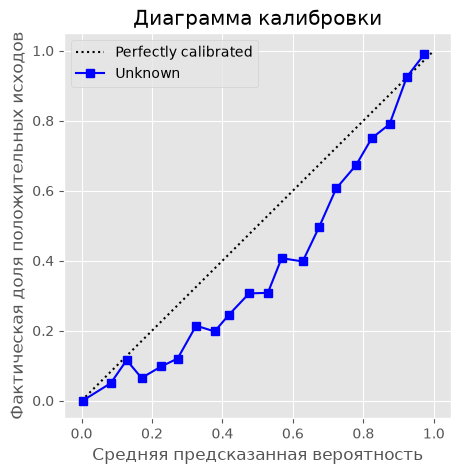

In [73]:
try:
    almost_final_model = FrozenEstimator(CatB_model)
except Exception:
    almost_final_model = CatB_model

y_pred_proba = almost_final_model.predict_proba(X_cal_test_gb)[:, 1]
calibration_curve_plotter(y_cal_test, y_pred_proba, n_bins = 20)

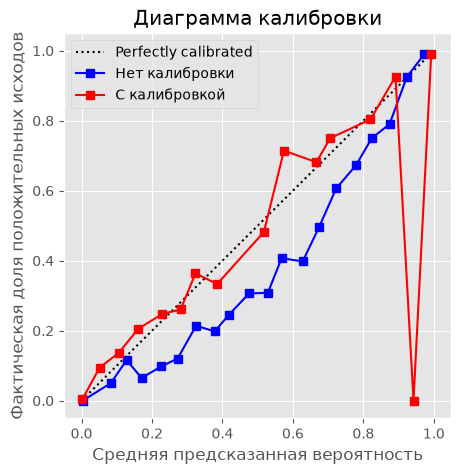

In [74]:
calibrated_final_model = CalibratedClassifierCV(estimator=almost_final_model, method='isotonic' )
calibrated_final_model.fit(X_cal_train_gb, y_cal_train)

y_pred_proba_cal = calibrated_final_model.predict_proba(X_cal_test_gb)[:, 1]
calibration_curve_plotter(y_cal_test, y_pred_proba, y_pred_proba_cal, label_list = ['Нет калибровки', 'С калибровкой'], n_bins=20)

In [75]:
pd.DataFrame([metrics_dict_calc_final(y_cal_test, y_pred_proba, cutoff = 0.5, fold_name = 'Cal', model_name = 'Non_calib'),
              metrics_dict_calc_final(y_cal_test, y_pred_proba_cal, cutoff = 0.5, fold_name = 'Cal', model_name = 'Calib')])

,model_name,fold_name,IR_abs_mil,IR_share,Refusal_Dynamic,False_Refuse_Share,Occupancy_Dynamic,Brier_Score_Loss,ECE,MCE,Accuracy,Precision,Recall,F1,Roc_Auc,PR_Auc
0,Non_calib,Cal,43.179,53.384518,82.075472,5.152542,21.979068,0.130725,0.094034,0.229969,0.791864,0.601036,0.820755,0.693918,0.894436,0.790959
1,Calib,Cal,46.724,57.766774,71.108491,8.305085,12.844910,0.116768,0.024424,0.942303,0.825424,0.690722,0.711085,0.700755,0.893998,0.772634


Калибровка улучшила показатели `brier_score_loss`, `ECE` и ухудшила `MCE`. Калибровка действительно улучшила калибровочную кривую на новых данных для калибратора.

<a id='p6e'></a>

---

### Определение порога и анализ матрицы классификаций

[К Содержимому проекта](#contents)

Определим порог, максимизирующий `IR`, на калибровочной и тестовой выборке. А также зафискисруем итоговую модель вместе с порогом в отдельный оберточный класс.

In [76]:
y_pred_proba_cal = calibrated_final_model.predict_proba(X_cal_test_gb)[:, 1]
res_l = []
for cutoff in [0.1, 0.2, 0.3, 0.4, 0.5, 0.53, 0.6, 0.7, 0.8]:
    dct = {'cutoff' : cutoff}
    dct = dct | metrics_dict_calc_final(y_cal_test, y_pred_proba_cal, cutoff = cutoff, fold_name = 'Cal', model_name = 'CatBoost')
    res_l.append(dct)

pd.DataFrame(res_l)

,cutoff,model_name,fold_name,IR_abs_mil,IR_share,Refusal_Dynamic,False_Refuse_Share,Occupancy_Dynamic,Brier_Score_Loss,ECE,MCE,Accuracy,Precision,Recall,F1,Roc_Auc,PR_Auc
0,0.10,CatBoost,Cal,23.992,29.662599,95.754717,1.220339,43.196955,0.116768,0.024424,0.942303,0.680000,0.472093,0.957547,0.632399,0.893998,0.772634
1,0.20,CatBoost,Cal,38.005,46.987624,88.207547,3.389831,29.210276,0.116768,0.024424,0.942303,0.757966,0.549192,0.882075,0.676923,0.893998,0.772634
2,0.30,CatBoost,Cal,44.124,54.552873,81.014151,5.457627,20.694577,0.116768,0.024424,0.942303,0.797966,0.612299,0.810142,0.697462,0.893998,0.772634
3,0.40,CatBoost,Cal,46.724,57.766774,71.108491,8.305085,12.844910,0.116768,0.024424,0.942303,0.825424,0.690722,0.711085,0.700755,0.893998,0.772634
4,0.50,CatBoost,Cal,46.724,57.766774,71.108491,8.305085,12.844910,0.116768,0.024424,0.942303,0.825424,0.690722,0.711085,0.700755,0.893998,0.772634
5,0.53,CatBoost,Cal,41.540,51.357516,52.358491,13.694915,4.709800,0.116768,0.024424,0.942303,0.829492,0.817680,0.523585,0.638390,0.893998,0.772634
6,0.60,CatBoost,Cal,40.692,50.310325,51.061321,14.067797,4.471931,0.116768,0.024424,0.942303,0.827458,0.821632,0.510613,0.629818,0.893998,0.772634
7,0.70,CatBoost,Cal,31.632,39.108960,37.146226,18.067797,1.902950,0.116768,0.024424,0.942303,0.805763,0.887324,0.371462,0.523691,0.893998,0.772634
8,0.80,CatBoost,Cal,29.062,35.931531,33.608491,19.084746,1.427212,0.116768,0.024424,0.942303,0.798983,0.904762,0.336085,0.490112,0.893998,0.772634


**Выводы:**

Максимум по `IR_share` достигается при 0.4 - 0.5. Здесь следует отметить, что модель не проходит по одной из трех бизнес требований на калибровочной выборке:
1. `IR_s` около `58%`, что более 50%. Здесь успех.
2. `False_Refuse_Share` <= 10%, а именно `8.3%`.
3. Загрузка отеля `Occupancy_Dynamic` не более 8%, сейчас `13%`. Упрощенная формула расчета: `Occupancy_Dynamic` = 100*(1 - `TN`/(`Общее количество бронирований` - `Фактические отмены`)), а здесь дробь характеризует то, насколько хорошо модель определяет отрицательный класс (отсутствие отмены бронирования и фактическое заселение). В идеале этот показатель должен равняться 0%.

Также от бизнеса предлагалось рассматривать:
- Динамика доли отмен - `Refusal_Dynamic` = `71%`. Данный показатель исходя из формулы расчета тем лучше, чем он ближе к 100%: `Refusal_Dynamic` = 100*(1 - `FN`/`Фактические отмены`). Дробь в данной формуле характеризует долю пропущенных моделью отмен бронирований. В идеале `FN = 0`, а значит показатель стремится к 100%.

В данный момент это может не так критично, поскольку у нас наблюдается изменение данных во времени. Например, количество отзывов накапливается. Возможно, что показатели на тесте будут достигнуты.

<span style="font-size: 14px;">**Анализ матрицы классификаций**</span>

Зафиксируем модель и оценим стабильность модели.

In [84]:
class ThresholdClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, model, preproc, cutoff=0.5):
        self.model = model
        self.cutoff = cutoff
        self.preproc = preproc

    def fit(self, X, y=None):
        X_prep = self.preproc.transform(X)
        self.model.fit(X_prep, y)
        return self

    def predict_proba(self, X):
        X_prep = self.preproc.transform(X)
        return self.model.predict_proba(X_prep)

    def predict(self, X):
        X_prep = self.preproc.transform(X)
        proba = self.model.predict_proba(X_prep)[:,1]
        return (proba >= self.cutoff).astype(int)

    def __getattr__(self, name):
        if name in ("model", "threshold") or name.startswith("__"):
            raise AttributeError(name)
        model = self.__dict__.get("model")
        if model is None:
            raise AttributeError(name)
        return getattr(model, name)

cutoff = 0.45
final_model = ThresholdClassifier(calibrated_final_model,GB_prep,cutoff)

In [85]:
y_pred_cal = final_model.predict(X_cal)
y_pred_test = final_model.predict(X_test)

print(color.RED + color.BOLD + 'Калибровочная выборка:' + '\n' + color.END)
print(classification_report(y_cal, y_pred_cal, digits=2))
print(color.RED + color.BOLD + 'Тестовая выборка:' + '\n' + color.END)
print(classification_report(y_test, y_pred_test, digits=2))

Калибровочная выборка:

              precision    recall  f1-score   support

           0       0.88      0.87      0.88      4156
           1       0.70      0.72      0.71      1744

    accuracy                           0.83      5900
   macro avg       0.79      0.80      0.79      5900
weighted avg       0.83      0.83      0.83      5900

Тестовая выборка:

              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4388
           1       0.85      0.84      0.85      1509

    accuracy                           0.92      5897
   macro avg       0.90      0.89      0.90      5897
weighted avg       0.92      0.92      0.92      5897



In [86]:
def plot_conf_matr(y_true, y_pred, figsize = (10,5), title = 'Матрица ошибок'):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=figsize)
    fig = sns.heatmap(cm, annot=True, fmt='.2f', cmap='YlGnBu',
                      linewidths=0.5, cbar=False, annot_kws={'size': 10})
    plt.title(title, fontsize=16)
    plt.xlabel('Предсказанный класс', fontsize=14)
    plt.ylabel('Настоящий класс', fontsize=14)
    fig.tick_params(axis='both', labelsize=12)
    plt.show()

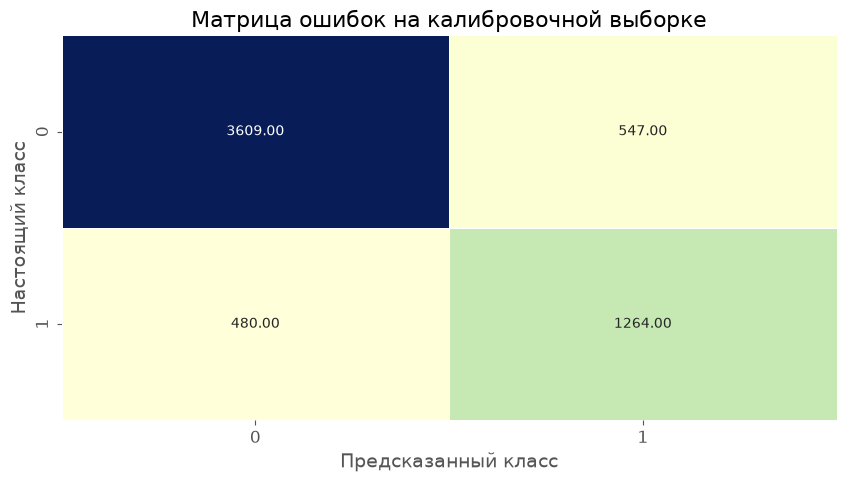

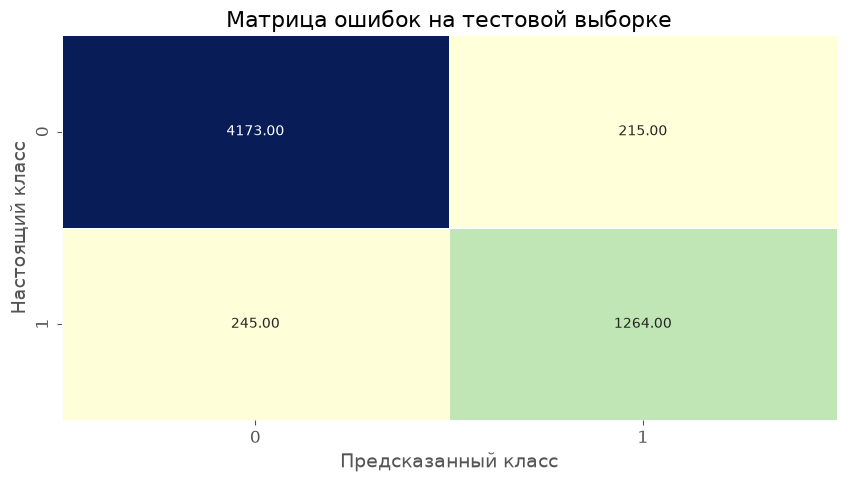

In [87]:
plot_conf_matr(y_cal, y_pred_cal, title = 'Матрица ошибок на калибровочной выборке')
plot_conf_matr(y_test, y_pred_test, title = 'Матрица ошибок на тестовой выборке')

In [88]:
try:
    joblib.dump(final_model, '../models/Final_model.joblib')
except Exception:
    joblib.dump(final_model, 'Final_model.joblib')

try:
    loaded_best = joblib.load('./../models/Final_model.joblib')
except Exception:
    loaded_best = joblib.load('Final_model.joblib')

y_pred_proba_train = loaded_best.predict_proba(X_train_val)[:, 1]
y_pred_proba_cal = loaded_best.predict_proba(X_cal)[:, 1]
y_pred_proba_test = loaded_best.predict_proba(X_test)[:, 1]

dummy = DummyClassifier()
dummy.fit(X_train_val,y_train_val)
y_pred_proba_train_dum = dummy.predict_proba(X_train_val)[:, 1]
y_pred_proba_cal_dum = dummy.predict_proba(X_cal)[:, 1]
y_pred_proba_test_dum = dummy.predict_proba(X_test)[:, 1]

pd.DataFrame([
    metrics_dict_calc_final(y_train_val, y_pred_proba_train, cutoff = cutoff, fold_name = 'Train-Val', model_name = 'loaded_model'),
    metrics_dict_calc_final(y_cal, y_pred_proba_cal, cutoff = cutoff, fold_name = 'Cal', model_name = 'loaded_model'),
    metrics_dict_calc_final(y_test, y_pred_proba_test, cutoff = cutoff, fold_name = 'Test', model_name = 'loaded_model'),
    metrics_dict_calc_final(y_train_val, y_pred_proba_train_dum, cutoff = cutoff, fold_name = 'Train-Val', model_name = 'DummyClassifier'),
    metrics_dict_calc_final(y_cal, y_pred_proba_cal_dum, cutoff = cutoff, fold_name = 'Cal', model_name = 'DummyClassifier'),
    metrics_dict_calc_final(y_test, y_pred_proba_test_dum, cutoff = cutoff, fold_name = 'Test', model_name = 'DummyClassifier')
])

C:\Users\EA\JupyterCode\ML_Module_3\ml-env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\EA\JupyterCode\ML_Module_3\ml-env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\EA\JupyterCode\ML_Module_3\ml-env\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,model_name,fold_name,IR_abs_mil,IR_share,Refusal_Dynamic,False_Refuse_Share,Occupancy_Dynamic,Brier_Score_Loss,ECE,MCE,Accuracy,Precision,Recall,F1,Roc_Auc,PR_Auc
0,loaded_model,Train-Val,260.118,55.786931,69.459821,9.035974,15.519731,0.129778,0.014002,0.118878,0.800361,0.652853,0.694598,0.673079,0.869990,0.733281
1,loaded_model,Cal,99.298,63.826539,72.477064,8.135593,13.161694,0.115939,0.012212,0.942303,0.825932,0.697957,0.724771,0.711111,0.897732,0.782274
2,loaded_model,Test,123.036,66.256587,83.764082,4.154655,4.899727,0.057269,0.028596,0.413597,0.921994,0.854632,0.837641,0.846051,0.976366,0.925074
3,DummyClassifier,Train-Val,0.000,0.000000,0.000000,29.587169,0.000000,0.208332,0.000000,0.000000,0.704128,0.000000,0.000000,0.000000,0.500000,0.295872
4,DummyClassifier,Cal,0.000,0.000000,0.000000,29.559322,0.000000,0.208218,0.000278,0.000278,0.704407,0.000000,0.000000,0.000000,0.500000,0.295593
5,DummyClassifier,Test,0.000,0.000000,0.000000,25.589283,0.000000,0.192010,0.039979,0.039979,0.744107,0.000000,0.000000,0.000000,0.500000,0.255893


**Выводы:**

1. Модель превосходит требуемые показатели эффективности на всех выборках. В абсолютных значениях доход компании в случае внедрения, потенциально, повысится на `99` и `123` миллионов рублей на калибровочных и тестовых данных (IR_a).
2. Сама модель превосходит `BaseLine` - `DummyClassifier` (он никогда не отменяет брони) и является явно лучшим вариантом по сравнению со случайным угадыванием.
3. Если рассматривать ошибки модели, то до калибровки она имела высокий `Recall` и низкий `Precision`, что логично в условиях того, какую именно метрику мы максимизируем:
    - `IR = IR_после - IR_до = 0*TN - 71500*FP + 109500*TP - 129000*FN`. В данном случае нет симметрии по отношению к тому, что модели выгоднее предположить положительный исход (Positive класс) или отрицательный (Negative класс).  
    - Общее распределение по классам у нас 0.7 (класс 0) и 0.3 (класс 1), тода ожидаемая выгода от выбора класса 0 составляет: -38700. Ожидаемая выгода от выбора класса 1 для модели составит: -50050 + 32850 = -17200.
    - В таком случае статистически мы получаем, что предсказывать класс 0 в случае неуверенности гораздо менее выгодно, чем предсказывать 1. Разница почти в два раза, что подталкивает построенные модели в условиях максимизации `IR` к тому, что они начинают чаще ставить единицы (отмены бронирования), чем нули. А это приводит к тому, что самые лучшие модели с относительно высоким `Recall` и низким `Precision`.
4. После калибровки распределение вероятностей изменилось, теперь модель имеет `Precision` выше `Recall`, хотя `Recall` достаточно близок. В целом после калибровки модель стала более сбалансирована и старается не так сильно ставить 1 (отмены) для бронирований, как раньше. В настоящий момент времени модель более часто ошибается с классом 0 (отсутствие отмены), чем с классом 1 в абсолютных значениях. Хотя в относительных значениях модель более точно предсказывает класс 0, что заметно по более высокому `Precision` для него в обоих выборках, что опять-таки логично исходя из формулы ключевой метрики.
5. Сама модель хоть и немного повышает понижает загруженность отеля (около 3.3%), но повышает доход (около 61%) на всех выборках. Поскольку по ключевому показателю для бизнеса модель достаточно стабильна. Однако, общая стабильность желает лучшего, технические показатели сильно скачут при переходе от выборки к выборке. Такое поведение вполне возможно не связано с самой моделью, а с качеством данных для ее обучения и тестирования. Было отмечено: 
    - Наблюдается сильное падение по количеству бронирований начиная с некоторого года. Причем это заметно и в рамках распределения целевой переменной
    - В датафрейме с бронированием отсутствует `customer_id`, что мешает объединение таблиц. Хотя он явно был при создании таблицы, иначе некоторые признаки не могли бы быть созданы (например, `previous_cancellations`). Его отсутствие также не позволяет создать дополнительные признаки, которые бы усилили модель (например, оставил-ли клиент после последнего бронирования отзыв или нет) и тому подобное.
    - Исправление этих недостатков позволит улучшить качество модели и повысить ее полезность для бизнеса.
    - Перед внедрением рекомендуется повторить процесс обучения и сделать отбор наиболее сильных признаков. Сами признаки рассматриваются ниже.

<a id='p6f'></a>

---

### Оценка важности признаков

[К Содержимому проекта](#contents)

Оценим результаты моделей на стандартном пороге.

In [89]:
def plot_feature_figs(model, X_val, model_name='Unknown', figsize = (10,6), feature_names=None):
    print(color.BOLD + color.BLUE + model_name + '\n' + color.END)
    
    explainer = shap.TreeExplainer(model)
    
    #X_val = X_val.toarray()
    #X_val = np.asarray(X_val, dtype=np.float64)
    
    shap_values = explainer.shap_values(X_val)
    
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
    elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
        shap_values = shap_values[:, :, 1]
    
    
    # Bar plot — средние абсолютные SHAP-значения
    fig, ax = plt.subplots(figsize=figsize)
    shap.summary_plot(shap_values, X_val, plot_type="bar", feature_names=feature_names, max_display=20, 
                      plot_size=None, show=False)
    plt.title(f"Глобальная важность признаков (средний |SHAP|) для {model_name}", fontsize=14)
    plt.gcf().set_size_inches(figsize[0], figsize[1])
    plt.tight_layout()
    plt.show()
    plt.close()
    
    #importances = pd.Series(model.feature_importances_, index=feature_names)
    #importances = importances.sort_values(ascending=True)
    #plt.figure(figsize=(8, 5))
    #plt.barh(importances.index, importances.values, color='lightseagreen')
    #plt.xlabel('Важность признака')
    #plt.title('Важность признаков в дереве решений')
    #plt.show()
    
    # Summary Plot для всех признаков
    plt.figure(figsize=figsize)
    shap.summary_plot(shap_values, X_val, feature_names=feature_names, show=False, plot_size=figsize)
    plt.title(f"SHAP Summary Plot для {model_name}", fontsize=14)
    plt.tight_layout()
    plt.show()
    
    print('\n\n')

CatBoost



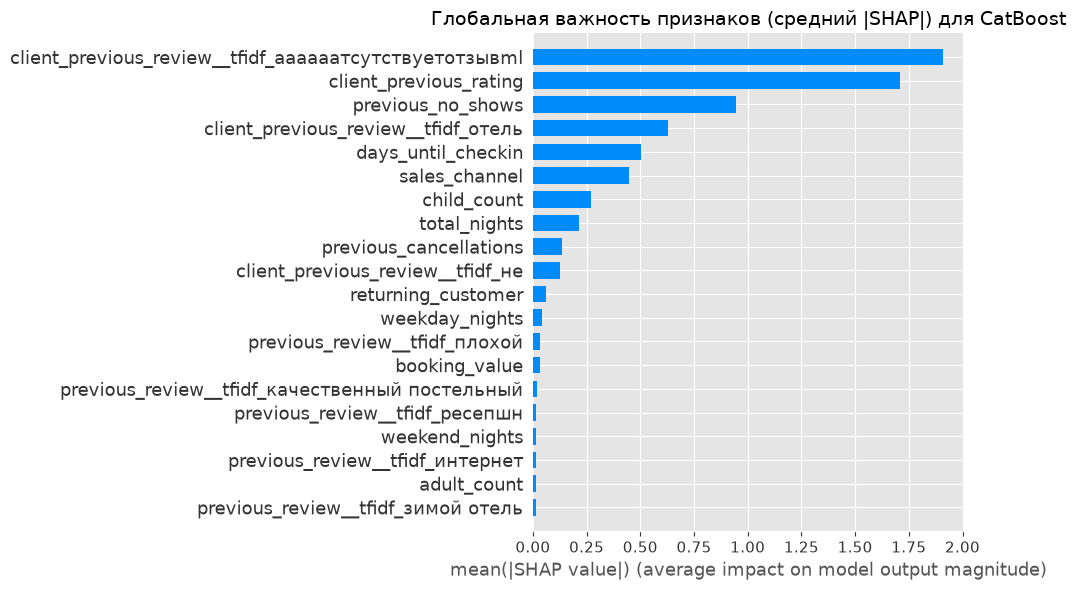

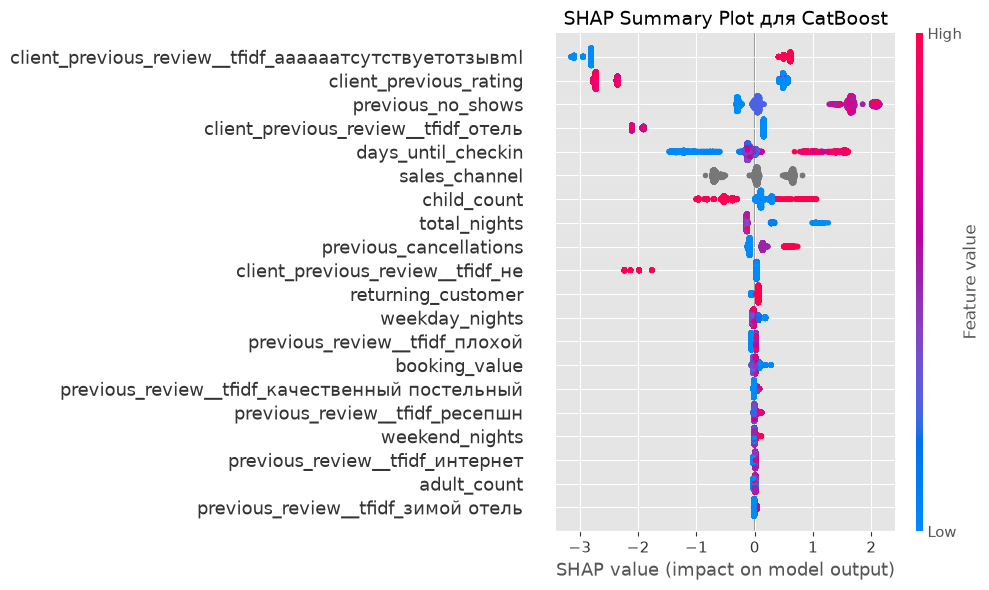

In [90]:
X_test_prep_gb = GB_prep.transform(X_test)
plot_feature_figs(CatB_model, X_test_prep_gb, 'CatBoost', feature_names=feature_names)

**Выводы:**

Наиболее сильное влияние на модель оказывают следующие признаки:
1. `client_previous_rating` - предыдущий рейтинг по отзыву клиента: чем выше значение рейтинга, тем менее вероятна отмена бронирования.
2. `previous_no_shows` - сколько раз клиент ранее не появлялся: чем больше значение, тем более веротна отмена бронирования.
3. `days_until_checkin` - сколько времени осталось до заезда: чем больше дней для заезда, тем больше вероятность отмены бронирования и, наоборот, чем меньше значении, тем менее вероятна отмена.
4. `sales_channel` - тип бронирования. Для разных видов бронирования разное среднее значение вероятности отмены бронирования. 
5. `child_count` - количество забронированных мест для детей. Большое количество детей уменьшает вероятность отмены бронирования.
6. `returning_customer` - возвращаюшийся клиент. Если клиент бывал ранее в отели - вероятность отмены бронирования немного выше.
7. `total_nights` - количество будних дней в бронировании. Если таких дней мало, то клиент с большей вероятностью отменит бронирование.
8. `previous_cancellations` - если клиент много отменял броней в прошлом, то он с большей вероятностью отменит их и в будущем.
9. Заметно влияние отдельных слов на поведение моделей. Самым важным является - флаг отсутствия отзыва. Заметны и другие отдельные слова, в том числе от общего фона за предыдущий день.

Остальные признаки оказывают заметно более слабое значение на целевую переменную и дальше в топе идут признаки в виде отдельных слов из отзывов клиента или за предыдущий день. В целом здесь стоит отметить несколько дополнительных моментов:
1. Отсутствие влияния месяца заезда или месяца бронирования (сезонности) на вероятность отмены брони. Это странно, т.к., например, зимой в курортных отелях вероятность отмены брони отличается от этой же вероятности летом.
2. На вероятность отмены бронирования слабо влияют стоимостные показатели, такие как `booking_value`, `meal_plan`, `parking_included`, `customer_special_requests`, `price_per_night`, что не подтверждает гипотиз вида: премиальные клиенты реже отменяют бронь. 

Стоит также отметить, что влияние прошлого отзыва для клиента достаточно сильно, а значит, возможно, стоит разделять клиентов и построить разные модели для прогнозирования их поведения. Если клиент заезжает впервые то для него использовать одну модель. А если он был ранее в отеле, то другую.

<a id='p7'></a>

---

### Итоговые выводы и рекомендации

[К Содержимому проекта](#contents)

**Экономическая эффективность модели**

Для оценки экономической эффективности модели `CatBoost` рассчитаны показатели дополнительного дохода, динамики отмен бронирований и изменения загрузки отеля. В расчётах учитывались средняя выручка с бронирования, потери от отмен, стоимость повторного бронирования и затраты на обработку ложных срабатываний.

По результатам оценки на тестовой выборке получены следующие показатели бизнес-метрик:

| Метрика | Значение | Целевое ограничение |
|---|---:|---:|
| **Абсолютный дополнительный доход (IR_abs)** | 123,04 млн руб. | — |
| **Относительный прирост дохода (IR_share)** | 66,26% | не менее 50% |
| **Доля ложных отказов (False_Refuse_Share)** | 4,15% | не более 10% |
| **Изменение загрузки (Occupancy_Dynamic)** | 4,90% | не более 8% |
| **Динамика отмен (Refusal_Dynamic)** | 83,76% | — |

Относительный прирост дохода превышает целевое значение, а изменение загрузки укладывается в установленное ограничение. Расчёты показывают потенциальную экономическую целесообразность использования модели. Перед внедрением необходимо проверить показатели по исходной матрице ошибок и подтвердить результаты на реальных данных.

**Проделанная работа**

В ходе проекта был проведён анализ данных о бронированиях и отзывах клиентов сети отелей UrbanStay. Данные очищены от дубликатов, обработаны пропуски и аномальные значения, стандартизированы категории признаков. Затем таблицы бронирований и отзывов были объединены с учётом временного порядка, чтобы избежать утечки информации из будущего.

В процессе feature engineering созданы дополнительные признаки: общее количество ночей, число гостей, стоимость за ночь, циклические признаки месяца, стоимость на одного гостя и доли ночей в будни и выходные от общего числа. Также подготовлены текстовые отзывы для векторизации.

Для прогнозирования отмен обучены и сравнены `Logistic Regression`, `Random Forest` и модели градиентного бустинга. Лучший результат показала **CatBoost**. Для работы с дисбалансом классов использовалась балансировка весов, а калибровка вероятностей позволила улучшить качество оценки риска.

На тестовой выборке итоговая модель показала следующие метрики:

| Метрика | Значение |
|---|---:|
| Accuracy | 92,20% |
| Precision | 85,46% |
| Recall | 83,76% |
| F1-score | 84,61% |
| ROC-AUC | 0,9764 |
| PR-AUC | 0,9251 |
| Brier Score | 0,0573 |
| ECE | 0,0286 |
| MCE | 0,4136 |

**Рекомендации для бизнеса**

1. Использовать прогноз риска отмен для приоритизации работы с бронированиями. Следует выделить бронирования с высокой прогнозной вероятностью отмены и организовать для них дополнительные напоминания, подтверждение намерения приехать или персональную коммуникацию. При этом необходимо оценивать эффективность каждого действия отдельно, чтобы не увеличивать затраты на клиентов, которые и без вмешательства приехали бы в отель.
2. Улучшить сбор и использование истории клиентов. Рекомендуется восстановить полноценную связь между бронированиями и клиентами, включая `customer_id`. Это позволит точнее учитывать историю отмен, неявок, предыдущих оценок и обращений гостей. Также необходимо проверить происхождение повторяющихся текстов отзывов и качество данных перед промышленным внедрением модели.
3. Возможно, стоит рассмотреть создание двух моделей:
    - модель для людей, заезжающих впервые;
    - модель для клиентов, посетивших ранее отель.
4. Организовать регулярный мониторинг модели и качества обслуживания. После внедрения следует ежемесячно отслеживать долю отмен, загрузку, относительный и абсолютный прирост дохода, а также технические метрики модели. При ухудшении результатов следует пересматривать порог классификации, состав признаков и параметры обучения.

**Итоговое заключение**

В ходе проекта выполнен полный цикл построения модели машинного обучения для прогнозирования отмен бронирований: от загрузки и анализа исходных данных до создания новых признаков, сравнения алгоритмов, подбора гиперпараметров, калибровки вероятностей и оценки экономического эффекта. Наилучший результат показала модель `CatBoost`. На тестовой выборке относительный прирост дохода составил около 66,26% при расчётном абсолютном эффекте около 123,04 млн рублей. Таким образом, целевой показатель относительного прироста дохода не менее 50% достигнут. Рекомендация: перейти к пилотному внедрению модели с контролем бизнес-показателей, регулярной проверкой качества прогнозов и последующей корректировкой порога классификации на основании реальных результатов работы отеля.

**Ссылка на проект на GitHub:**

https://github.com/AlexandrEvdokimov/UrbanStay_Cancellation_Risk